In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

/home/gespejogutierrez/mambaforge/envs/climada_env/lib/python3.10/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 12.0.1. Please consider upgrading.
  warnings.warn(


In [2]:
#pip install -e .

In [ ]:
os.chdir('/home/gespejogutierrez/data/TC_0012')

In [2]:
from datetime import datetime, timedelta
import logging
import os

logging.getLogger('climada.hazard.tc_tracks_forecast').setLevel(logging.WARNING)

def fetch_multiple_ecmwf_data(base_folder, start_date, end_date, event_name):
    current_date = start_date
    forecast_variables = {}  # Dictionary to store forecast variables

    while current_date <= end_date:
        for utc_hour in [0,12]:  # Only check 0 UTC and 12 UTC
            date_folder = current_date.replace(hour=utc_hour, minute=0, second=0).strftime("%Y%m%d%H%M%S")
            folder_path = os.path.join(base_folder, date_folder)

            if os.path.exists(folder_path):
                forecast = TCForecast()
                files_to_fetch = []
                for root, dirs, files in os.walk(folder_path):
                    for file in files:
                        if event_name in file:
                            files_to_fetch.append(os.path.join(root, file))

                if files_to_fetch:
                    print(f"Fetching data for {date_folder}")
                    forecast.fetch_ecmwf(files=files_to_fetch)
                    variable_name = f"{event_name}_{date_folder}"
                    forecast_variables[variable_name] = forecast
                else:
                    print(f"No data found for {date_folder}")
            else:
                print(f"Folder not found: {date_folder}")

        current_date += timedelta(days=1)

    return forecast_variables

Folder not found: 20190310000000
Fetching data for 20190310120000
Reading CXML file: /home/gespejogutierrez/programs/RDA_Data/20190310120000/z_tigge_c_ecmf_20190310120000_ifs_glob_prod_all_glo.xml


/home/gespejogutierrez/climada_petals/climada_petals/hazard/tc_tracks_forecast.py:641: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  all_storms_df = pd.read_csv(


Initial parsed data contains 882 tracks.
Applying subsetting for event 'Idai' and ensemble members.
Folder not found: 20190311000000
Fetching data for 20190311120000
Reading CXML file: /home/gespejogutierrez/programs/RDA_Data/20190311120000/z_tigge_c_ecmf_20190311120000_ifs_glob_prod_all_glo.xml


/home/gespejogutierrez/climada_petals/climada_petals/hazard/tc_tracks_forecast.py:641: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  all_storms_df = pd.read_csv(


Initial parsed data contains 835 tracks.
Applying subsetting for event 'Idai' and ensemble members.
Folder not found: 20190312000000
Fetching data for 20190312120000
Reading CXML file: /home/gespejogutierrez/programs/RDA_Data/20190312120000/z_tigge_c_ecmf_20190312120000_ifs_glob_prod_all_glo.xml


/home/gespejogutierrez/climada_petals/climada_petals/hazard/tc_tracks_forecast.py:641: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  all_storms_df = pd.read_csv(


Initial parsed data contains 824 tracks.
Applying subsetting for event 'Idai' and ensemble members.
Folder not found: 20190313000000
Fetching data for 20190313120000
Reading CXML file: /home/gespejogutierrez/programs/RDA_Data/20190313120000/z_tigge_c_ecmf_20190313120000_ifs_glob_prod_all_glo.xml


/home/gespejogutierrez/climada_petals/climada_petals/hazard/tc_tracks_forecast.py:641: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  all_storms_df = pd.read_csv(


Initial parsed data contains 724 tracks.
Applying subsetting for event 'Idai' and ensemble members.
Folder not found: 20190314000000
Fetching data for 20190314120000
Reading CXML file: /home/gespejogutierrez/programs/RDA_Data/20190314120000/z_tigge_c_ecmf_20190314120000_ifs_glob_prod_all_glo.xml


/home/gespejogutierrez/climada_petals/climada_petals/hazard/tc_tracks_forecast.py:641: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  all_storms_df = pd.read_csv(


Initial parsed data contains 826 tracks.
Applying subsetting for event 'Idai' and ensemble members.
dict_keys(['Idai_20190310120000', 'Idai_20190311120000', 'Idai_20190312120000', 'Idai_20190313120000', 'Idai_20190314120000'])


In [ ]:
# Set your parameters here
base_folder = "/home/gespejogutierrez/data/TC_0012"
start_date = datetime(2023,2 ,19, 12, 0)
end_date = datetime(2023, 2, 24, 12, 0)
event_name = "FREDDY"

# Fetch data and store forecast variables
forecast_variables = fetch_multiple_ecmwf_data(base_folder, start_date, end_date, event_name)

In [ ]:
# construct centroids among Mozambique and La Reunion 
from climada.hazard import Centroids
min_lat, max_lat, min_lon, max_lon = -28,-9, 30, 42
cent = Centroids.from_pnt_bounds((min_lon, min_lat, max_lon, max_lat), res=0.12)
cent.check()
cent.plot();

In [ ]:
from climada.hazard.trop_cyclone import TropCyclone 
from datetime import datetime

# Create an empty dictionary to store TropCyclone objects
tc_objects = {}

# Create dictionaries instead of lists to store TropCyclone names and ensemble variables
tc_names = {}
ens_variables = {}

for variable_name, forecast in forecast_variables.items():
    if f"{event_name}" in variable_name:
        ensemble_variable_name = f"ens_{variable_name}"
        ensemble_forecast = forecast.subset({'is_ensemble': True})
        ensemble_forecast.equal_timestep(time_step_h=0.5)
        globals()[variable_name] = forecast
        globals()[ensemble_variable_name] = ensemble_forecast

        print(f"Variable {ensemble_variable_name} created as the ensemble of {variable_name}")
        
        # Extract the date and time information from the variable name
        date_time_str = variable_name.split("_", 2)[-1]
        date_time_obj = datetime.strptime(date_time_str, "%Y%m%d%H%M%S")

        # Create a TropCyclone object from ensemble forecast data
        tc_object_name = f"{event_name}_{date_time_obj.strftime('%Y%m%d%H%M%S')}"
        
        # Assign name and ensemble variable to respective keys
        timestamp_key = f"{event_name}_{date_time_obj.strftime('%Y%m%d%H%M%S')}"
        tc_names[timestamp_key] = TropCyclone.from_tracks(ensemble_forecast, centroids=cent)

        # Assign ensemble variable name to the dict
        ens_variables[f"ens_{timestamp_key}"] = ensemble_forecast
        print(f"Variable ens_{timestamp_key} added to ens_variables")

In [ ]:
import copy

# Assuming tc_names is a dictionary in the provided format

# Create a dictionary to store the copied and modified TropCyclone objects
new_tc_names = {}

for tc_name, tc_object in tc_names.items():
    # Get a deep copy of the TropCyclone object
    tc_088_copy = copy.deepcopy(tc_object)
    
    # Handle potential AttributeError
    try:
        # Calculate and update the new intensity data
        new_data = tc_088_copy.intensity.data * 0.88
        tc_088_copy.intensity.data = new_data
        
        # Create a new key with the 'new_' prefix
        new_key = 'new_' + tc_name
        
        # Add the updated TropCyclone object to the new dictionary
        new_tc_names[new_key] = tc_088_copy
    except AttributeError:
        print(f"{tc_name} has no attribute 'intensity'")

# Now, new_tc_names contains the copied and modified TropCyclone objects

In [ ]:
##EXPOSURE 

In [ ]:
## keep working with the tracks with intensity in Mozambique
##Getting data infrastructure 
import geopandas as gpd
import pandas as pd
from pathlib import Path
import shapely
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from datetime import datetime

# on climada_petals branch feature/networks until merged!
#from climada_petals.engine.networks import nw_utils as nwu  ## 
from climada_petals.entity.exposures.openstreetmap import osm_dataloader as osm
from climada_petals.util.constants import DICT_GEOFABRIK

# on climada_python develop branch
from climada.util import coordinates as u_coords
from climada.entity.exposures.base import Exposures
from climada.entity.impact_funcs import ImpactFunc, ImpactFuncSet
#from climada.entity import ImpactFunc, ImpactFuncSet
from climada.entity import ImpfTropCyclone
from climada.engine import Impact
from climada.hazard.base import Hazard
from climada.util import lines_polys_handler as u_lp
from climada.util.api_client import Client

from climada_petals.entity.exposures.openstreetmap import osm_dataloader as osm
from climada_petals.util.constants import DICT_GEOFABRIK

from climada.util import coordinates as u_coords
from climada.hazard.base import Hazard

In [5]:
import rasterio
import pyproj

print(f"Rasterio Version: {rasterio.__version__}")
print(f"PROJ Version: {pyproj.__version__}")

Rasterio Version: 1.4.3
PROJ Version: 3.5.0


In [6]:
import pyproj
import rasterio
import os

print(f"PROJ Version (pyproj): {pyproj.__version__}")
print(f"PROJ Database Path: {pyproj.datadir.get_data_dir()}")
print(f"Rasterio Version: {rasterio.__version__}")
print(f"PROJ_LIB Environment Variable: {os.environ.get('PROJ_LIB')}")

PROJ Version (pyproj): 3.5.0
PROJ Database Path: /home/gespejogutierrez/mambaforge/envs/climada_env/share/proj
Rasterio Version: 1.4.3
PROJ_LIB Environment Variable: None


In [10]:
new_tc_names

{}

In [8]:
new_tc_names ['new_Freddy_20190310120000'].intensity.data

KeyError: 'new_Idai_20190310120000'

In [9]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/home/gespejogutierrez/programs/FREDDY_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'forecast_variables.pkl', 'wb') as file:
    pickle.dump(forecast_variables, file)

with open(save_dir_pickle + 'new_tc_names.pkl', 'wb') as file:
    pickle.dump(new_tc_names, file)

In [10]:
## EXPOSURE 

In [11]:
## keep working with the tracks with intensity in Mozambique
##Getting data infrastructure 
import geopandas as gpd
import pandas as pd
from pathlib import Path
import shapely
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from datetime import datetime

# on climada_petals branch feature/networks until merged!
#from climada_petals.engine.networks import nw_utils as nwu  ## 
from climada_petals.entity.exposures.openstreetmap import osm_dataloader as osm
from climada_petals.util.constants import DICT_GEOFABRIK

# on climada_python develop branch
from climada.util import coordinates as u_coords
from climada.entity.exposures.base import Exposures
from climada.entity.impact_funcs import ImpactFunc, ImpactFuncSet
#from climada.entity import ImpactFunc, ImpactFuncSet
from climada.entity import ImpfTropCyclone
from climada.engine import Impact
from climada.hazard.base import Hazard
from climada.util import lines_polys_handler as u_lp
from climada.util.api_client import Client

from climada_petals.entity.exposures.openstreetmap import osm_dataloader as osm
from climada_petals.util.constants import DICT_GEOFABRIK

from climada.util import coordinates as u_coords
from climada.hazard.base import Hazard

In [12]:
# general paths & constants
PATH_DATA = '/home/gespejogutierrez/programs/data/infrastructure/'
PATH_DATA_OSM = '/home/gespejogutierrez/programs/data/openstreetmap/' # path to search for osm.pbf files and to download to if not existing
PATH_DATA_HVMV = PATH_DATA +'power_global/grid.gpkg' # path of this file from gridfinder. needs to be downloaded.
PATH_DATA_PP = PATH_DATA +'power_global/global_power_plant_database.csv' # path of this file from WRI global power plant db. needs to be downloaded.
#PATH_DATA_CT = PATH_DATA +'cell_towers/opencellid_global_1km_int.tif' # path of this file from worldbank open data gridded celltowers. needs to be downloaded.
PATH_DATA_POP = PATH_DATA + 'population/' # path to search for population files and to download to if not existing
PATH_SAVE = '/home/gespejogutierrez/programs/data/infrastructure/Mozambique_results_'

In [13]:
cntry = 'Mozambique'
iso3 = u_coords.country_to_iso(cntry)

try:
    path_osm_cntry = PATH_DATA_OSM+DICT_GEOFABRIK[iso3][-1]+'-latest.osm.pbf'
except KeyError:
    path_osm_cntry = PATH_DATA_OSM+f'{cntry}'+'-latest.osm.pbf'
path_worldpop_cntry_1km = PATH_DATA_POP + f'{iso3.lower()}_ppp_2020_1km_Aggregated_UNadj.tif'
path_worldpop_cntry_100m = PATH_DATA_POP + f'{iso3.lower()}_ppp_2020_UNadj.tif'
path_el_consump_cntry = PATH_DATA + f'power/Electricity consumption per capita - {cntry}.csv'
path_elgen_cntry = PATH_DATA + f'power/Electricity generation by source - {cntry}.csv'
path_el_imp_exp_cntry = PATH_DATA + f'power/Electricity imports vs. exports - {cntry}.csv'
path_save_cntry = PATH_SAVE + f'{iso3}/'
if not os.path.isdir(path_save_cntry):
    os.mkdir(path_save_cntry)

In [14]:
###SUBNATIONAL DIVISION 
geofile_MOZ = '/home/gespejogutierrez/programs/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [15]:
# re-load: the data that I have already proceeed for Mozambique 
gdf_pp = gpd.read_feather(path_save_cntry+'power_plant')
gdf_power = gpd.read_feather(path_save_cntry+'power_component')
gdf_powerlines= gpd.read_feather(path_save_cntry+ 'power_line')
gdf_health = gpd.read_feather(path_save_cntry+ 'health')
gdf_educ = gpd.read_feather(path_save_cntry+'education')
#gdf_cells= gpd.read_feather(path_save_cntry+'celltower')
gdf_roads = gpd.read_feather(path_save_cntry+'road')

##################### POPULATION 
from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster(path_worldpop_cntry_1km)
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
#gdf_worldpop_MDG.gdf

/home/gespejogutierrez/programs/climada_python/climada/util/coordinates.py:2746: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  df_val['geometry'] = gpd.GeoSeries(


In [16]:
# Rename the 'value' column to 'people'
gdf_worldpop_MOZ.gdf = gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'})

In [17]:
gdf_worldpop_MOZ.gdf

,longitude,latitude,people,geometry
0,30.219583,-10.471250,0.0,POINT (30.21958 -10.47125)
1,30.227917,-10.471250,0.0,POINT (30.22792 -10.47125)
2,30.236250,-10.471250,0.0,POINT (30.23625 -10.47125)
3,30.244583,-10.471250,0.0,POINT (30.24458 -10.47125)
4,30.252917,-10.471250,0.0,POINT (30.25292 -10.47125)
...,...,...,...,...
2509195,40.802917,-26.862916,0.0,POINT (40.80292 -26.86292)
2509196,40.811250,-26.862916,0.0,POINT (40.81125 -26.86292)
2509197,40.819583,-26.862916,0.0,POINT (40.81958 -26.86292)
2509198,40.827917,-26.862916,0.0,POINT (40.82792 -26.86292)


In [18]:
def _find_duplicates(overlap_gdf):
    indices_dupl = np.unique([index_right for index_right, index_left in zip(overlap_gdf.index_right, overlap_gdf.index_left)
                    if index_right != index_left])
    indices_dupl = indices_dupl[:int(len(indices_dupl/2))] # only first half of duplicates should be removed!
    return indices_dupl

def _remove_duplicates(orig_gdf, indices_dupl):
    indices_keep = list(set(orig_gdf.index).difference(set(indices_dupl)))
    return orig_gdf.loc[indices_keep]

def find_remove_duplicates(orig_gdf):
    if 'index' in orig_gdf.columns:
        orig_gdf = orig_gdf.drop('index', axis=1)
    overlap_gdf = orig_gdf.sjoin(orig_gdf)
    if 'index_left' not in overlap_gdf.columns:
        overlap_gdf = overlap_gdf.reset_index()
        overlap_gdf = overlap_gdf.rename({'index':'index_left'}, axis=1)  
    indices_dupl = _find_duplicates(overlap_gdf)
    return _remove_duplicates(orig_gdf, indices_dupl) 

In [19]:
gdf_health_MOZ = gdf_health.reset_index(drop=True)
gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
gdf_health_MOZ = find_remove_duplicates(gdf_health_MOZ)
gdf_health_MOZ['geometry'] = gdf_health_MOZ.geometry.centroid

In [20]:
gdf_educ_MOZ = gdf_educ.reset_index(drop=True)
gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.buffer(0.001) # ca. 100m buffer in epsg4326; decrease if you think that's too much
gdf_educ_MOZ = find_remove_duplicates(gdf_educ_MOZ)
gdf_educ_MOZ['geometry'] = gdf_educ_MOZ.geometry.centroid
gdf_roads_MOZ = gdf_roads

In [21]:
## CLASSIFICATION OF THE HOSPITAL BY LEVELS

In [22]:
# Apply the 'determine_level' function to create the 'levels' column
from climada_petals.hazard.IMP_TRACKFORECAST import determine_level
gdf_health_MOZ['levels'] = gdf_health_MOZ.apply(determine_level, axis=1)

# Remove rows where 'levels' is None
gdf_health_MOZ= gdf_health_MOZ.dropna(subset=['levels'])

In [23]:
# Call the function to remove rows with NaN in the 'name' column
from climada_petals.hazard.IMP_TRACKFORECAST import remove_rows_with_nan
gdf_health_MOZ = remove_rows_with_nan(gdf_health_MOZ)

In [24]:
# Example usage:
# Apply the 'determine_level' function to create the 'levels' column
from climada_petals.hazard.IMP_TRACKFORECAST import determine_level_for_MOZ
gdf_health_MOZ['levels'] = gdf_health_MOZ.apply(determine_level_for_MOZ, axis=1)

In [25]:
import re
import copy
from climada_petals.hazard.IMP_TRACKFORECAST import exposure_from_points, exposure_from_lines, exposure_from_points_with_value, exposure_from_points_pp
from climada_petals.hazard.IMP_TRACKFORECAST import create_exp_dict
# Your exposure calculations
exp_h1_MOZ = exposure_from_points(copy.deepcopy(gdf_health_MOZ), {'TC': 'health_Eberenz'})
exp_h2_MOZ = exposure_from_points(copy.deepcopy(gdf_health_MOZ), {'TC': 'health_deltares'})

##########

exp_ed1_MOZ = exposure_from_points(copy.deepcopy(gdf_educ_MOZ), {'TC': 'health_Eberenz'})
exp_ed2_MOZ = exposure_from_points(copy.deepcopy(gdf_educ_MOZ), {'TC': 'health_deltares'})

##########
exp_rd1_MOZ = exposure_from_lines(copy.deepcopy(gdf_roads_MOZ), {'TC': 'health_Eberenz'}, res=500)
exp_rd2_MOZ = exposure_from_lines(copy.deepcopy(gdf_roads_MOZ), {'TC': 'health_deltares'}, res=500)

###########
exp_pp1_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat1'}) 
exp_pp2_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat2'}) 
exp_pp3_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat3'}) 
exp_pp4_MOZ = exposure_from_points_with_value(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat4'}) 

###########

exp_pp5_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat1'}) 
exp_pp6_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat2'}) 
exp_pp7_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat3'}) 
exp_pp8_MOZ = exposure_from_points_pp(copy.deepcopy(path_worldpop_cntry_1km), {'TC': 'cat4'}) 
##  I defined already LitPop_MOZ at the beginning, but in this case I am addying the function 4 in the exposure 
#exp_h5_MOZ.gdf.impf_ = 4 
# Create and sort the dictionary
exp_dict = create_exp_dict(locals())

2024-11-12 18:57:36,042 - climada.util.lines_polys_handler - WARNING - 5791 lines with a length < 10*resolution were found. Each of these lines is disaggregate to one point. Reaggregatint values will thus likely lead to overestimattion. Consider chosing a smaller resolution or filter out the short lines. 
2024-11-12 18:58:37,431 - climada.util.lines_polys_handler - WARNING - 5791 lines with a length < 10*resolution were found. Each of these lines is disaggregate to one point. Reaggregatint values will thus likely lead to overestimattion. Consider chosing a smaller resolution or filter out the short lines. 


/home/gespejogutierrez/programs/climada_python/climada/util/coordinates.py:2746: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('geometry')` to explicitly set the active geometry column.
  df_val['geometry'] = gpd.GeoSeries(
/home/gespejogutierrez/programs/climada_python/climada/util/coordinates.py:2746: FutureWarning: You are adding a column named 'geometry' to a GeoDataFrame constructed without an active geometry column. Currently, this automatically sets the active geometry column to 'geometry' but in the future that will no longer happen. Instead, either provide geometry to the GeoDataFrame constructor (GeoDataFrame(... geometry=GeoSeries()) or use `set_geometry('ge

In [26]:
###Save exp_dict
with open(save_dir_pickle + 'exp_dict.pkl', 'wb') as file:
    pickle.dump(exp_dict, file)

In [27]:
from climada_petals.hazard.IMP_TRACKFORECAST import make_impfset
impf_set_tc = make_impfset(ImpFuncsCIWindMoz())
impf_set_tc

In [28]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
imph1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_health_df = copy.deepcopy(gdf_health_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_var_name1 = f'imph1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact1_obj = Impact()
    impact1_obj.calc(eval(f'exp_h1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    imph1[impact_var_name1] = impact1_obj

2024-11-12 19:00:41,055 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:41,722 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:41,746 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:41,769 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:41,791 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [29]:
imph1 ['imph1_MOZ_Freddy_20190310120000'].imp_mat.data

array([0.13874727, 0.09459862, 0.09941095, ..., 0.03974818, 0.03974818,
       0.03974818])

In [30]:
import copy
from climada.engine import Impact

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
imph2 = {}

# Iterate through track variables in new_tc_names
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_health_df = copy.deepcopy(gdf_health_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Access the track object from new_tc_names dictionary
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts
    impact_var_name2 = f'imph2_{country_code}_{track_name_variable}'

    # Initialize and calculate the Impact object
    impact2_obj = Impact()
    impact2_obj.calc(eval(f'exp_h2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the imph2 dictionary
    imph2[impact_var_name2] = impact2_obj

2024-11-12 19:00:42,067 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,092 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,127 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,150 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,167 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [31]:
## educational impacts

In [32]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
ed1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_educ_df = copy.deepcopy(gdf_educ_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_edu1 = f'ed1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_edu1_obj = Impact()
    imp_edu1_obj.calc(eval(f'exp_ed1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    ed1[imp_edu1] = imp_edu1_obj

2024-11-12 19:00:42,246 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,267 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,287 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,307 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,325 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [33]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
ed2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_educ_df = copy.deepcopy(gdf_educ_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_edu2 = f'ed2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_edu2_obj = Impact()
    imp_edu2_obj.calc(eval(f'exp_ed2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    ed2[imp_edu2] = imp_edu2_obj

2024-11-12 19:00:42,346 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,358 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,369 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,380 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:42,392 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [34]:
## Roads

In [35]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
rd1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_roads_df = copy.deepcopy(gdf_roads_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_rd1 = f'rd1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
     # Initialize and calculate the Impact object
    imp_rd1_obj = Impact()
    imp_rd1_obj.calc(eval(f'exp_rd1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    #imp_rd1_obj = u_lp.impact_pnt_agg(imp_rd1_obj,  eval(f'exp_rd1_{country_code}').gdf, u_lp.AggMethod.SUM)
    
    # Add the impact object to the dictionary with its name as the key
    rd1[imp_rd1] = imp_rd1_obj

2024-11-12 19:00:42,536 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:43,431 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:44,512 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:45,611 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:46,775 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [36]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
rd2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in new_tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_roads_df = copy.deepcopy(gdf_roads_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = new_tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    imp_rd2 = f'rd2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    imp_rd2_obj = Impact()
    imp_rd2_obj.calc(eval(f'exp_rd2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    #imp_rd2_obj = u_lp.impact_pnt_agg(imp_rd2_obj,  eval(f'exp_rd2_{country_code}').gdf, u_lp.AggMethod.SUM)
    
    # Add the impact object to the dictionary with its name as the key
    rd2[imp_rd2] = imp_rd2_obj

2024-11-12 19:00:48,039 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:49,549 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:50,800 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:52,433 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:00:53,939 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [37]:
rd2 ['rd2_MOZ_new_Idai_20190310120000'].at_event/500

array([27641.39953923, 17326.32444498, 29772.87225413, 11895.77175653,
       27303.73978282, 24007.7248007 , 26904.0225592 , 28026.42622889,
        7874.1658054 ,  9593.61613519, 23610.65422608, 28995.84003249,
       25610.11746354, 36457.40844645, 11285.33331432, 26304.04487349,
       17813.61005761, 12259.82873364, 23740.11161764, 11835.62249532,
        8752.92143472, 27780.18225132, 28153.07454411, 18741.41620987,
       33605.23216746, 25504.77594534, 21141.47120678, 25761.30970834,
       21907.55923821, 27261.47687018, 28975.13827257, 27035.52113411,
       29890.66627414, 28813.31427955, 34034.27361997, 16167.54112527,
       26012.17309403, 22467.95583953, 28267.8035022 , 26790.10072508,
       23673.23476855, 24079.16489868, 32305.06184341, 27893.71845607,
           0.        , 20546.28451802,   114.73562599, 23698.64839132,
       28113.33907775,  9071.13461508, 25597.4813014 ])

In [38]:
## people impact

In [39]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp1 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name1 = f'impp1_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp1_obj = Impact()
    impact_pp1_obj.calc(eval(f'exp_pp1_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp1[impact_pp_name1] = impact_pp1_obj

2024-11-12 19:00:55,918 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:00,834 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:05,739 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:10,150 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:14,340 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [40]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp2 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name2 = f'impp2_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp2_obj = Impact()
    impact_pp2_obj.calc(eval(f'exp_pp2_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp2[impact_pp_name2] = impact_pp2_obj

2024-11-12 19:01:18,071 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:22,159 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:26,511 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:30,315 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:34,391 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [41]:
impp2 ['impp2_MOZ_Idai_20190310120000'].imp_mat.data

array([0.49772953, 0.49772953, 0.49772953, ..., 1.        , 1.        ,
       1.        ])

In [42]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp3 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name3 = f'impp3_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp3_obj = Impact()
    impact_pp3_obj.calc(eval(f'exp_pp3_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp3[impact_pp_name3] = impact_pp3_obj

2024-11-12 19:01:37,282 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:41,355 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:46,823 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:01:54,456 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:01,843 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [43]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp4 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name4 = f'impp4_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp4_obj = Impact()
    impact_pp4_obj.calc(eval(f'exp_pp4_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp4[impact_pp_name4] = impact_pp4_obj

2024-11-12 19:02:07,149 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:15,431 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:23,855 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:32,182 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:40,226 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [44]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp5 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name5 = f'impp5_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp5_obj = Impact()
    impact_pp5_obj.calc(eval(f'exp_pp5_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp5[impact_pp_name5] = impact_pp5_obj

2024-11-12 19:02:46,057 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:49,238 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:52,334 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:55,503 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:02:58,655 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [45]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp6 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name6 = f'impp6_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp6_obj = Impact()
    impact_pp6_obj.calc(eval(f'exp_pp6_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp6[impact_pp_name6] = impact_pp6_obj

2024-11-12 19:03:01,470 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:04,481 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:07,278 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:09,686 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:12,468 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [46]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp7 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name7 = f'impp7_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp7_obj = Impact()
    impact_pp7_obj.calc(eval(f'exp_pp7_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp7[impact_pp_name7] = impact_pp7_obj

2024-11-12 19:03:14,154 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:16,516 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:18,743 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:21,116 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:23,872 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [47]:
import copy
from climada.engine import Impact  

# Specify the country code
country_code = 'MOZ'

# Initialize a dictionary to store all impact objects with their respective names
impp8 = {}

# Your tc_names and other required parameters must be defined before this section of the code. 
# Ensure that all necessary data and objects are adequately initialized.

# Iterate through track variables
for track_name_variable in tc_names:
    # Create a copy of the GeoDataFrame for health data based on the specified country
    if country_code == 'MOZ':
        gdf_worldpop_df = copy.deepcopy(gdf_worldpop_MOZ)
    else:
        # Handle other countries as needed
        pass

    # Assuming 'track_name_variable' is the key in tc_names dictionary, referring to track objects
    track_obj = tc_names[track_name_variable]

    # Create Impact objects and calculate impacts for impact1
    impact_pp_name8 = f'impp8_{country_code}_{track_name_variable}'  # Customized name for impact1
    
    # Initialize and calculate the Impact object
    impact_pp8_obj = Impact()
    impact_pp8_obj.calc(eval(f'exp_pp8_{country_code}'), impf_set_tc, track_obj, save_mat=True)
    
    # Add the impact object to the dictionary with its name as the key
    impp8[impact_pp_name8] = impact_pp8_obj

2024-11-12 19:03:26,651 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:29,107 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:31,024 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:33,610 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.
2024-11-12 19:03:35,227 - climada.engine.impact - WARNING - The use of Impact().calc() is deprecated. Use ImpactCalc().impact() instead.


In [49]:
with open(save_dir_pickle + 'imph1.pkl', 'wb') as file:
    pickle.dump(imph1, file)

In [50]:
with open(save_dir_pickle + 'ed1.pkl', 'wb') as file:
    pickle.dump(ed1, file)

In [51]:
# Save in pickle files
with open(save_dir_pickle + 'imph2.pkl', 'wb') as file:
    pickle.dump(imph2, file)
with open(save_dir_pickle + 'ed2.pkl', 'wb') as file:
    pickle.dump(ed2, file)
with open(save_dir_pickle + 'rd2.pkl', 'wb') as file:
    pickle.dump(rd2, file)
with open(save_dir_pickle + 'impp1.pkl', 'wb') as file:
    pickle.dump(impp1, file)
with open(save_dir_pickle + 'impp2.pkl', 'wb') as file:
    pickle.dump(impp2, file)
with open(save_dir_pickle + 'impp3.pkl', 'wb') as file:
    pickle.dump(impp3, file)
with open(save_dir_pickle + 'impp5.pkl', 'wb') as file:
    pickle.dump(impp5, file)
with open(save_dir_pickle + 'impp6.pkl', 'wb') as file:
    pickle.dump(impp6, file)
with open(save_dir_pickle + 'impp7.pkl', 'wb') as file:
    pickle.dump(impp7, file)

In [47]:
## CALCULATING THE MEAN IMPACT BY EXPOSURE

In [49]:
from climada_petals.hazard.IMP_TRACKFORECAST import calc_mean_for_impdict
mimpacts_all = {}  # Store all mean impacts here

# Iterate through the dictionaries and calculate the mean impacts
for prefix in ['imph','ed','rd', 'impp']:  # Use a list to iterate through both prefixes
    for i in range(1, 9):  # i will take values 1 through 3
        impact_dict_name = f"{prefix}{i}"  # Construct the name of the impact dictionary
        try:
            impact_dict = globals()[impact_dict_name]  # Retrieve the dictionary from globals
        except KeyError:
            print(f"Warning: {impact_dict_name} not found.")
            continue  # Skip to the next iteration if this impact dict is not found
        
        # Calculate the mean impacts and store them in the mimpacts_all dictionary
        mimpacts_all[impact_dict_name] = calc_mean_for_impdict(impact_dict)

In [51]:
with open(save_dir_pickle + 'mimpacts_all.pkl', 'wb') as file:
    pickle.dump(mimpacts_all, file)

In [51]:
######add all of them at once in a dictionary 
from climada_petals.hazard.IMP_TRACKFORECAST import calc_imp_overallexp
timpacts_all = {}  # Store all mean impacts here

# Iterate through the dictionaries and calculate the total impacts
for prefix in ['imph','ed','rd', 'impp']:  # Use a list to iterate through both prefixes
    for i in range(1, 9):  # i will take values 1 through 5
        imph_dict_name = f"{prefix}{i}"  # Construct the name of the imph dictionary
        try:
            imph_dict = globals()[imph_dict_name]  # Retrieve the dictionary from globals
        except KeyError:
            print(f"Warning: {imph_dict_name} not found.")
            continue  # Skip to the next iteration if this imph dict is not found
    
        # Calculate the mean impacts and store them in the all_mean_impacts dictionary
        timpacts_all[imph_dict_name] = calc_imp_overallexp(imph_dict)

In [52]:
### IT RENAMES ALL THE KEYS IN 5 DAYS ....  
# New key names in order
new_keys = ['4 days', '3 days', '2 days', '1 day', 'landfall']

# Renaming keys for each dictionary inside timpacts_all
for category in timpacts_all:
    timpacts_all[category] = dict(zip(new_keys, timpacts_all[category].values()))

In [53]:
### TOTAL IMPACT BY LEAD TIME

In [54]:
timpacts_all_imph2 = timpacts_all['imph2']

In [55]:
# Calculate mean and standard deviation for each key
# Define a mapping from keys to more readable lead time names
from scipy import stats

lead_time = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'}
results = []
for key, values in timpacts_all_imph2.items():
    mean_value = np.mean(values)
    std_dev = np.std(values)
    skewness = stats.skew(values)

    readable_lead_time = lead_time.get(key, key)  # Use the mapping
    results.append([readable_lead_time, mean_value, std_dev, skewness])

# Creating a DataFrame from the results
results_df = pd.DataFrame(results, columns=['Lead Time', 'Mean', 'Standard Deviation', 'Skewness'])

results_df

,Lead Time,Mean,Standard Deviation,Skewness
0,4 days,25.955514,8.864984,-0.545086
1,3 days,29.071656,6.588458,0.446558
2,2 days,31.945481,4.708172,0.744016
3,1 day,33.553380,3.654077,0.604457
4,landfall,31.564591,2.802847,0.194475


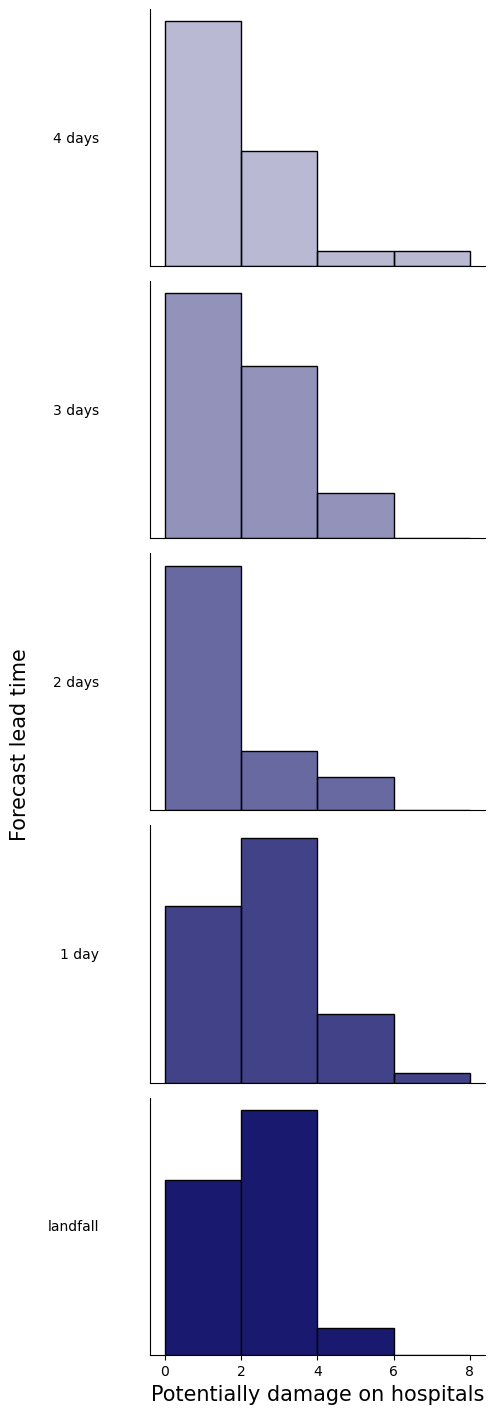

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

# Your existing setup
nrows = 5
lead_times = ['4 days', '3 days', '2 days', '1 day', 'landfall']
fig, axes = plt.subplots(nrows, 1, figsize=(5, 15))  # One column of plots

# Define the color for the histograms
dark_blue = "midnightblue"  # Dark blue color

for i, lead_time in enumerate(lead_times):
    # Calculate the alpha as a linear interpolation from 0.3 to 1 over the histograms
    alpha = 0.3 + (i / (nrows - 1) * 0.7)
    # Histogram for imph1
    sns.histplot(timpacts_all['imph1'][lead_time], ax=axes[i],
                 bins=[0,2,4,6,8],
                 color=dark_blue, alpha=alpha)
    # Remove x-axis labels for all but the last plot
    if i < nrows - 1:
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    else:
        axes[i].set_xlabel('Potentially damage on hospitals',fontsize=15)
        axes[i].tick_params(axis='x', which='both', bottom=True, labelbottom=True)
    # Remove y-axis labels for all plots
    axes[i].set_ylabel('')
    # Add the lead times as text on the far left
    axes[i].text(-0.15, 0.5, lead_time, transform=axes[i].transAxes,
                 ha='right', va='center')
    # Show y-axis line only on the leftmost side
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    # Show x-axis line for all plots
    axes[i].spines['bottom'].set_visible(True)

# Set the y-axis to have no ticks
plt.setp(axes, yticks=[])

# Set a common y-axis title aligned centrally with the figure
fig.text(0.02, 0.5, 'Forecast lead time', va='center', rotation='vertical',fontsize=15)

# Adjust layout with padding to provide space for common axis labels
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.show()

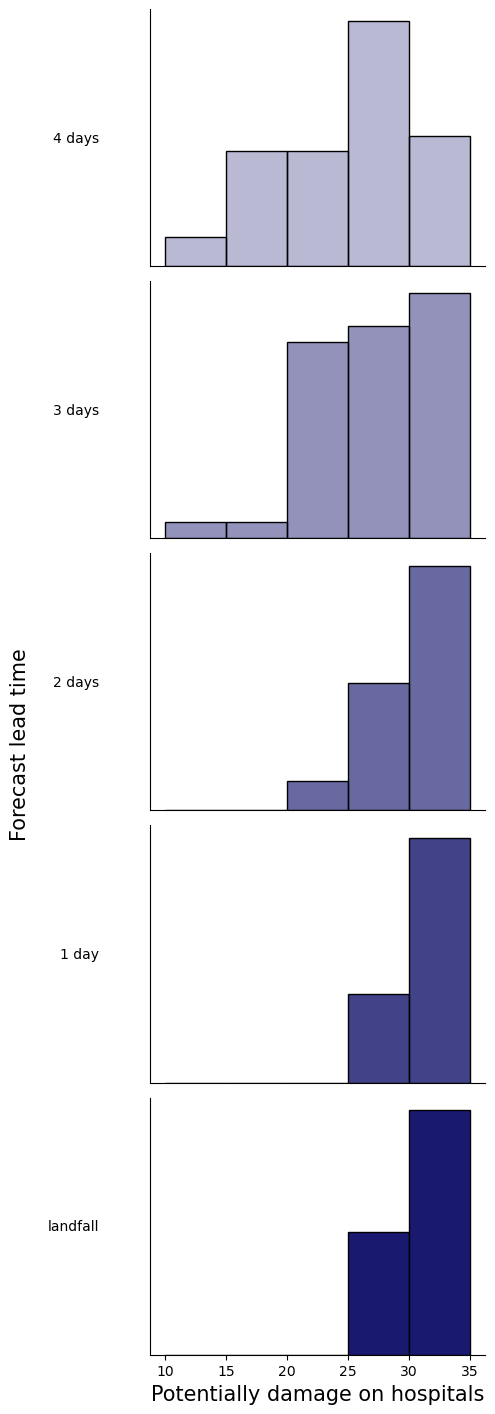

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

# Your existing setup
nrows = 5
lead_times = ['4 days', '3 days', '2 days', '1 day', 'landfall']
fig, axes = plt.subplots(nrows, 1, figsize=(5, 15))  # One column of plots

# Define the color for the histograms
dark_blue = "midnightblue"  # Dark blue color

for i, lead_time in enumerate(lead_times):
    # Calculate the alpha as a linear interpolation from 0.3 to 1 over the histograms
    alpha = 0.3 + (i / (nrows - 1) * 0.7)
    # Histogram for imph1
    sns.histplot(timpacts_all['imph2'][lead_time], ax=axes[i],
                 bins=[10,15,20,25,30,35],
                 color=dark_blue, alpha=alpha)
    # Remove x-axis labels for all but the last plot
    if i < nrows - 1:
        axes[i].set_xlabel('')
        axes[i].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    else:
        axes[i].set_xlabel('Potentially damage on hospitals',fontsize=15)
        axes[i].tick_params(axis='x', which='both', bottom=True, labelbottom=True)
    # Remove y-axis labels for all plots
    axes[i].set_ylabel('')
    # Add the lead times as text on the far left
    axes[i].text(-0.15, 0.5, lead_time, transform=axes[i].transAxes,
                 ha='right', va='center')
    # Show y-axis line only on the leftmost side
    axes[i].spines['left'].set_visible(True)
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    # Show x-axis line for all plots
    axes[i].spines['bottom'].set_visible(True)

# Set the y-axis to have no ticks
plt.setp(axes, yticks=[])

# Set a common y-axis title aligned centrally with the figure
fig.text(0.02, 0.5, 'Forecast lead time', va='center', rotation='vertical',fontsize=15)

# Adjust layout with padding to provide space for common axis labels
plt.tight_layout(rect=[0.05, 0.05, 1, 1])

plt.show()

In [58]:
## DATAFRAMES OF THE IMPACTS AND CONVERTING EXPOSURES TO DATAFRAMES DICTIONARIES
import pandas as pd
import numpy as np
import copy
from climada.entity import Exposures


# Your impact data
# ... [mimpacts_all definition, assumed to be defined above]
### THIS exp_df_fict is important to join it with the impact data that I am extracting from 
## here from mimpacts_all. In the last step I am converting exposures to dataframes to join it 
## with the impact values, which is important afterwards to join_dfs (data with mean impact plus
## exposure) 

# Converting the impact data into DataFrames
imp_df = {}  # A dictionary to store the impact data DataFrames

for imp_key, impacts in mimpacts_all.items():
    imp_df[imp_key] = pd.DataFrame.from_dict(impacts, orient='index').T

# Converting Exposure objects to DataFrames and saving in a new dictionary
exp_df_dict = {f"{key}_df": pd.DataFrame(copy.deepcopy(exp.gdf)) for key, exp in exp_dict.items()}

In [59]:
import geopandas as gpd

joined_dfs = {}

print("Keys in exp_df_dict:", exp_df_dict.keys())
print("Keys in imp_df:", imp_df.keys())

for prefix in [('exp_h', 'imph'), ('exp_ed','ed'),('exp_rd','rd'),('exp_pp', 'impp')]:
    for i in range(1, 9):  
        exp_key = f'{prefix[0]}{i}_MOZ_df'
        imp_key = f'{prefix[1]}{i}'
        
        print(f"Checking for keys: {exp_key}, {imp_key}")
        
        if exp_key in exp_df_dict and imp_key in imp_df:
            exp_reset = exp_df_dict[exp_key].reset_index(drop=True)
            imp_reset = imp_df[imp_key].reset_index(drop=True)
            
            if exp_reset.shape[0] != imp_reset.shape[0]:
                print(f"Number of rows does not match for {exp_key} and {imp_key}. Skipping.")
                continue
            
            joined_dfs[imp_key] = pd.concat([exp_reset, imp_reset], axis=1) 

Keys in exp_df_dict: dict_keys(['exp_h1_MOZ_df', 'exp_ed1_MOZ_df', 'exp_rd1_MOZ_df', 'exp_pp1_MOZ_df', 'exp_h2_MOZ_df', 'exp_ed2_MOZ_df', 'exp_rd2_MOZ_df', 'exp_pp2_MOZ_df', 'exp_pp3_MOZ_df', 'exp_pp4_MOZ_df', 'exp_pp5_MOZ_df', 'exp_pp6_MOZ_df', 'exp_pp7_MOZ_df', 'exp_pp8_MOZ_df'])
Keys in imp_df: dict_keys(['imph1', 'imph2', 'ed1', 'ed2', 'rd1', 'rd2', 'impp1', 'impp2', 'impp3', 'impp4', 'impp5', 'impp6', 'impp7', 'impp8'])
Checking for keys: exp_h1_MOZ_df, imph1
Checking for keys: exp_h2_MOZ_df, imph2
Checking for keys: exp_h3_MOZ_df, imph3
Checking for keys: exp_h4_MOZ_df, imph4
Checking for keys: exp_h5_MOZ_df, imph5
Checking for keys: exp_h6_MOZ_df, imph6
Checking for keys: exp_h7_MOZ_df, imph7
Checking for keys: exp_h8_MOZ_df, imph8
Checking for keys: exp_ed1_MOZ_df, ed1
Checking for keys: exp_ed2_MOZ_df, ed2
Checking for keys: exp_ed3_MOZ_df, ed3
Checking for keys: exp_ed4_MOZ_df, ed4
Checking for keys: exp_ed5_MOZ_df, ed5
Checking for keys: exp_ed6_MOZ_df, ed6
Checking for keys

# Save in pickle files
with open(save_dir_pickle + 'joined_dfs.pkl', 'wb') as file:
    pickle.dump(joined_dfs, file)

In [59]:
## EXPOSURES FORMAT 

In [61]:
from climada.entity.exposures import Exposures
from climada_petals.hazard.IMP_TRACKFORECAST import create_and_check_exposures
# Creating exposures_dict to store the created Exposures objects
exposures_dict = {key: create_and_check_exposures(df) for key, df in joined_dfs.items() 
                  if 'latitude' in df.columns and 'longitude' in df.columns}

In [62]:
# IMPACT PLOTTING THEREFORE WE NEED TO EXTRACT IT LONG,LAT,LEVELS. 
## ONCE ALL THE CALCULATION ARE DONE IN DATAFRAMES AND IN EXPOSURES, SUBSET ONLY THE TRACKS TO PLOT ACCORDING TO THE LEAD TIME FORECAST
## AND THE DAY THAT MAKES LANDFALL 

In [63]:
# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 5},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 10},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 30},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [64]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}


#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)


# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}

In [65]:
from datetime import datetime
import pandas as pd
from climada_petals.hazard.IMP_TRACKFORECAST import extract_points_to_plot
# Example usage (Assuming exposures_dict and the necessary key are available and that the gdf attribute of the instances in exposures_dict have the necessary columns.)
#exp_key = 'imph_1'
#date_forecast = '20230306060000'
#event_date = '20230311060000'

#results = perform_calculations(exposures_dict, exp_key, date_forecast, event_date)
p_imph1_plot = extract_points_to_plot(exposures_dict, 'imph1','20190310120000','20190314120000')
p_imph2_plot = extract_points_to_plot(exposures_dict, 'imph2','20190314120000','20190314120000')

Note: Calculating with lead time of 4 days.
Note: The event date and forecast date are the same.


In [66]:
exp_longitude = p_imph2_plot['longitude']
exp_latitude = p_imph2_plot['latitude']
exp_impact = p_imph2_plot['impact_data'] ['impact']
exp_levels = p_imph2_plot['level_data']
lead_time = p_imph2_plot ['lead_time']

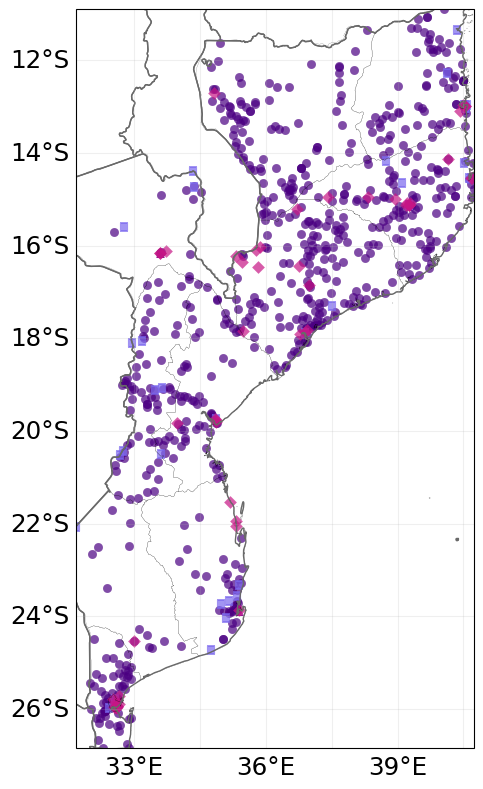

In [67]:
##PLOT EXPOSURE 
from climada_petals.hazard.IMP_TRACKFORECAST import plot_exposure
filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/MOZ_Exposures.jpg"
plotting_tracks = plot_exposure(exp_longitude,exp_latitude,exp_impact,exp_levels,filename,filename,gadm_MOZ)

In [68]:
## Plotting tracks 

In [69]:
import climada.util.plot as u_plot
import climada.util.coordinates as u_coord
import matplotlib.cm as cm_mp
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.collections import LineCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from climada.util.constants import ONE_LAT_KM, DEF_CRS, CMAP_EXPOSURES
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

SAFFIR_SIM_CAT = [17.49, 32.92, 42.7, 49.39, 58.13, 70.48, 1000]
CAT_NAMES = {
    -1: 'Tropical Depression',
    0: 'Tropical Storm',
    1: 'Hurricane Cat. 1',
    2: 'Hurricane Cat. 2',
    3: 'Hurricane Cat. 3',
    4: 'Hurricane Cat. 4',
    5: 'Hurricane Cat. 5',
}

#define the colourmap
color_ranges = [0, 0.02, 0.10, 0.20, 0.50,1.0]  # Add 1.01 to cover the entire range [0, 1]
colors = [(204 / 255, 255 / 255, 102 / 255, 0.1),   # Slightly transparent
    (204 / 255, 255 / 255, 102 / 255,0.9),     # Fully opaque
    (255 / 255, 255 / 255, 0 / 255, 0.9),    # More transparent
    (255 / 255, 153 / 255, 0 / 255, 0.9),
    (255 / 255, 0 / 255, 0 / 255, 0.9)]
# Create a custom colormap from the list of colors
my_cmap = ListedColormap(colors=colors)

# Create custom legend labels
legend_labels = [
    'No Damage (0.00 - 0.02)',
    'Minor Impact (0.02 - 0.10)',
    'Major Impact (0.10 - 0.20)',
    'Severe Impact (0.20 - 0.50)',
    'Destroyed (0.50 - 1.00)'
]
# Create legend patches based on the colors
legend_patches = [mpatches.Patch(color=colors[i], label=legend_labels[i]) for i in range(len(colors))]

# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Extracting values from points_to_plot
exp_longitude = p_imph2_plot['longitude']
exp_latitude = p_imph2_plot['latitude']
exp_impact = p_imph2_plot['impact_data'] ['impact']
exp_levels = p_imph2_plot['level_data']
lead_time = p_imph2_plot ['lead_time']

# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 40},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 40},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 40},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}

In [70]:
## PLOT WITH TRACKS AND WITHOUT TRACKS MOZAMBIQUIQUE AND ITS HOSPITALS LEVELS

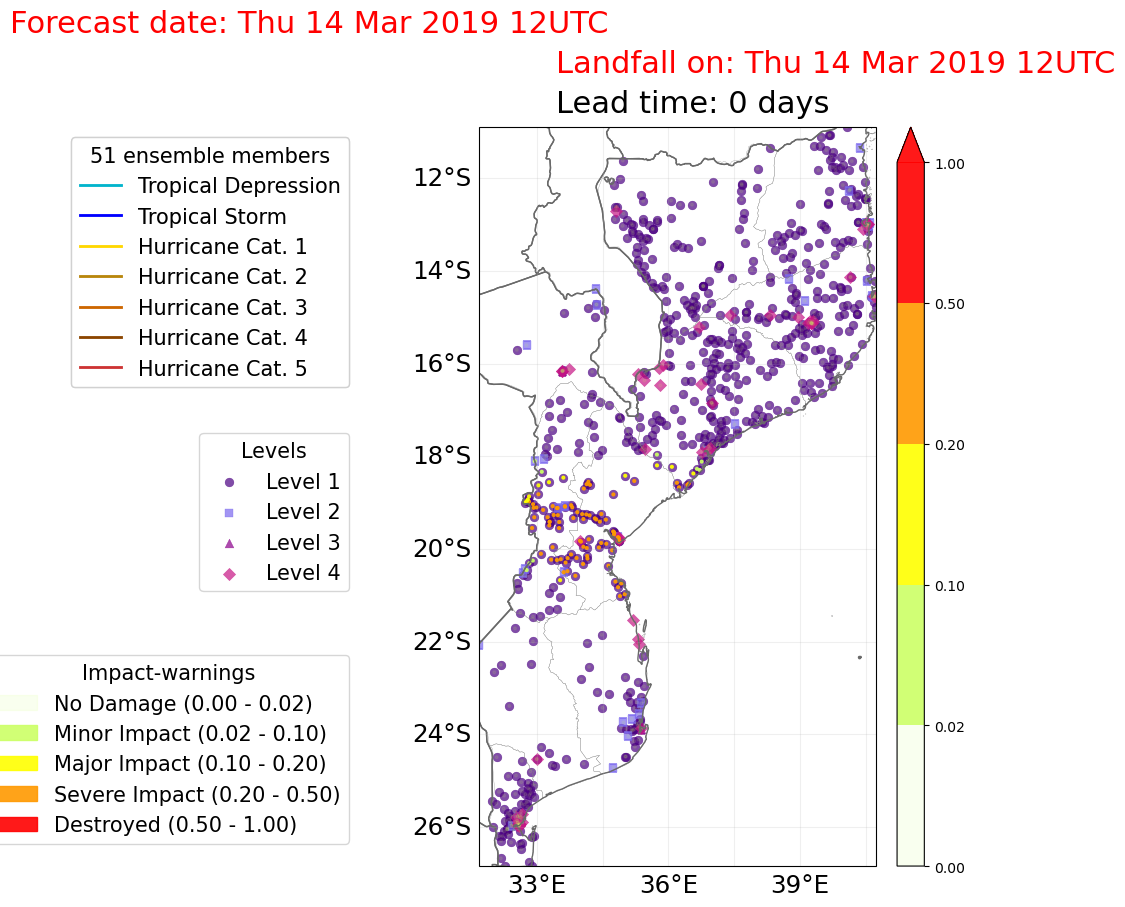

In [71]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_tracks 
filename= "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/MOZ_20190314120000_strucimpforecast_imph2_withouttracks.jpg"
plotting_tracks = plot_tracks(ens_variables ['ens_Idai_20190314120000'],
                 exp_longitude,exp_latitude,exp_impact,exp_levels,filename,0,gadm_MOZ,lead_time)

In [72]:
## PLOT WITH TRACKS THE IMPACT WITHOUT LEVELS OF THE HOSPITALS 

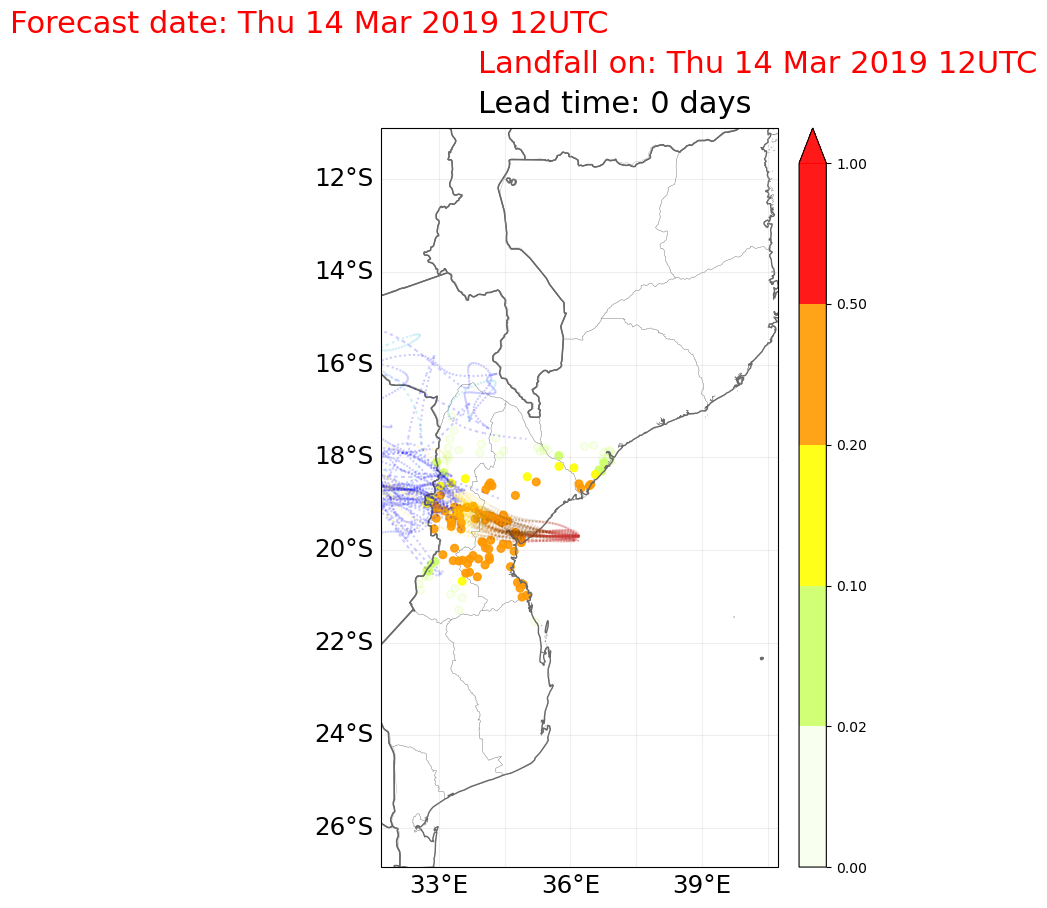

In [73]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_impact_track 
filename= "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/MOZ_20190314120000_strucimpforecast_imph2_impactonly.jpg"
plotting_tracks = plot_impact_track(ens_variables ['ens_Idai_20190314120000'],exp_levels,exp_impact,filename,0.2,gadm_MOZ,lead_time)

In [74]:
####PLOT WITHOUT LEGEND

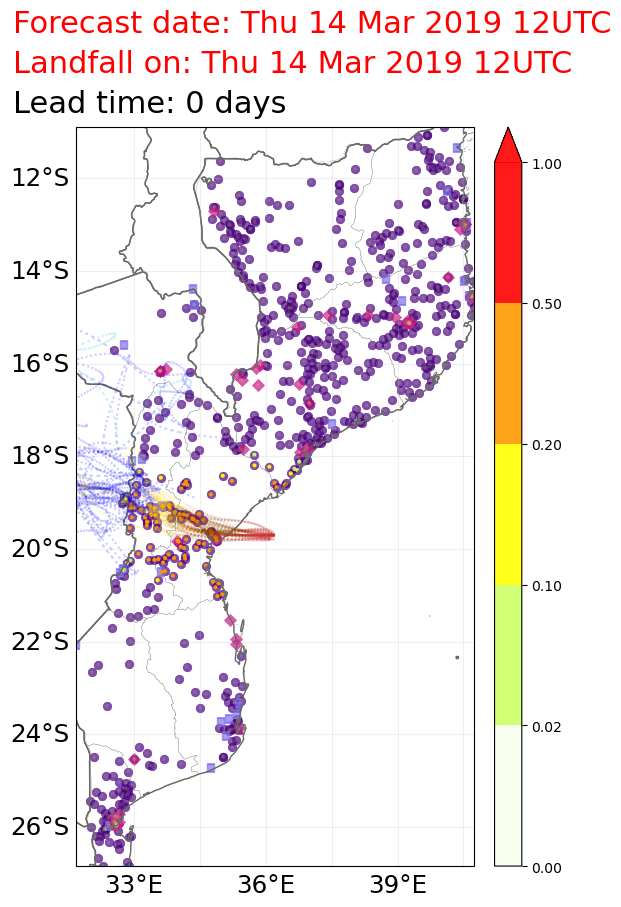

In [75]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_tracks_nolegend
filename= "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/MOZ_20190314120000_trucimpforecast_nolegend_imph2.jpg"
plotting_tracks_nolegend = plot_tracks_nolegend(ens_variables ['ens_Idai_20190314120000'],exp_longitude,exp_latitude,exp_impact,exp_levels,filename,
                                                0.2, gadm_MOZ, lead_time)

In [76]:
## CALCULATION FOR THE ROADS MEAN IMPACT OVER ALL THE POINTS

In [78]:
from climada_petals.hazard.IMP_TRACKFORECAST import impact_51ens_st
rd1_51ens = impact_51ens_st(rd1, 'rd1','MOZ_Idai')
rd2_51ens = impact_51ens_st(rd2, 'rd2','MOZ_new_Idai')

In [75]:
##join the points of the road among the 51 ensemble members 

In [79]:
# Example usage
from climada_petals.hazard.IMP_TRACKFORECAST import join_road_exp_51ens
rd1_mimpact = join_road_exp_51ens(rd1_51ens, exp_rd1_MOZ.gdf)
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_rd2_MOZ.gdf)

In [80]:
## scale the impact among the road 

In [81]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import mimpact_col_scale
mimpact_col_scale(rd2_mimpact, 'mean_impact', 500)
mimpact_col_scale(rd1_mimpact, 'mean_impact', 500)

In [79]:
####PLOT ROAD IMPACTS

In [80]:
from climada_petals.hazard.IMP_TRACKFORECAST import plot_road_impact
plot_road_impact(rd2_mimpact, gadm_MOZ, '/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/', '20190314120000')

In [81]:
###filter disrupted roads above 0.20 

In [82]:
# Define the threshold value (e.g., 0.20)
from climada_petals.hazard.IMP_TRACKFORECAST import filter_disruptrd_data
threshold = 0.20   ##severe damage

# Call the function to filter "mean_impact" values for all keys
disrupt_rd1 = filter_disruptrd_data(rd1_mimpact, threshold)
disrupt_rd2 = filter_disruptrd_data(rd2_mimpact, threshold)

In [83]:
disrupt_rd2 ['20190313120000']

,osm_id,mean_impact,geometry_orig
234,1005204544,0.318249,"LINESTRING (33.33626 -19.10024, 33.33671 -19.0..."
235,1005204545,0.318249,"LINESTRING (33.33769 -19.10116, 33.33818 -19.1..."
271,1005337451,0.338821,"LINESTRING (33.71293 -19.11910, 33.71269 -19.1..."
272,1005337452,0.338821,"LINESTRING (33.71489 -19.11963, 33.71500 -19.1..."
273,1005337453,0.338821,"LINESTRING (33.72115 -19.11939, 33.72107 -19.1..."
...,...,...,...
278091,990238041,0.326407,"LINESTRING (33.43524 -19.10554, 33.43514 -19.1..."
278264,991345635,0.360283,"LINESTRING (33.93766 -19.20643, 33.93764 -19.2..."
278265,991345636,0.360283,"LINESTRING (33.93578 -19.20485, 33.93620 -19.2..."
278341,998118039,0.326407,"LINESTRING (33.44524 -19.12687, 33.44583 -19.1..."


In [84]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [85]:
from climada_petals.hazard.IMP_TRACKFORECAST import create_points_geodfs_hfacilities,create_points_geodfs_CI,create_points_geodfs_pp
crs = gadm_MOZ_gdf.crs  # Replace with your actual CRS
points_geo_h1 = create_points_geodfs_hfacilities(imph1, exp_dict['exp_h1_MOZ'].gdf, crs)
points_geo_ed1 = create_points_geodfs_CI(ed1,exp_dict['exp_ed1_MOZ'].gdf,crs)
#points_geo_rd1 = create_points_geodfs_rd(rd1,gdf_roads_MOZ, crs)
#points_geo_pp1 = create_points_geodfs_pp(impp1,exp_dict['exp_pp1_MOZ'].gdf,crs)
######################################################################################
points_geo_h2 = create_points_geodfs_hfacilities(imph2, exp_dict['exp_h2_MOZ'].gdf, crs)
points_geo_ed2 = create_points_geodfs_CI(ed2,exp_dict['exp_ed2_MOZ'].gdf,crs)
#points_geo_rd2 = create_points_geodfs_rd(rd2,gdf_roads_MOZ, crs)
#points_geo_pp2 = create_points_geodfs_pp(impp2,exp_dict['exp_pp2_MOZ'].gdf,crs)
########################################################################################
points_geo_pp1 = create_points_geodfs_pp(impp1,exp_dict['exp_pp1_MOZ'].gdf,crs)
points_geo_pp3 = create_points_geodfs_pp(impp3,exp_dict['exp_pp3_MOZ'].gdf,crs)
#points_geo_pp4 = create_points_geodfs_pp(impp4,exp_dict['exp_pp4_MOZ'].gdf,crs)
points_geo_pp5 = create_points_geodfs_pp(impp5,exp_dict['exp_pp5_MOZ'].gdf,crs)
points_geo_pp6 = create_points_geodfs_pp(impp6,exp_dict['exp_pp6_MOZ'].gdf,crs)
points_geo_pp7 = create_points_geodfs_pp(impp7,exp_dict['exp_pp7_MOZ'].gdf,crs)
#points_geo_pp8 = create_points_geodfs_pp(impp8,exp_dict['exp_pp8_MOZ'].gdf,crs)

In [86]:
###Adding points for columns

In [87]:
from climada_petals.hazard.IMP_TRACKFORECAST import add_columns_in_geodata
#add_columns_in_geodata(points_geo_h1, mimpacts_all, 'imph1')
add_columns_in_geodata(points_geo_h2, mimpacts_all, 'imph2')
add_columns_in_geodata(points_geo_ed1, mimpacts_all, 'ed1')
add_columns_in_geodata(points_geo_ed2, mimpacts_all, 'ed2')
add_columns_in_geodata(points_geo_pp1, mimpacts_all, 'impp1')
#add_columns_in_geodata(points_geo_pp2, mimpacts_all, 'impp2')
add_columns_in_geodata(points_geo_pp3, mimpacts_all, 'impp3')
#add_columns_in_geodata(points_geo_pp4, mimpacts_all, 'impp4')
add_columns_in_geodata(points_geo_pp5, mimpacts_all, 'impp5')
add_columns_in_geodata(points_geo_pp6, mimpacts_all, 'impp6')
add_columns_in_geodata(points_geo_pp7, mimpacts_all, 'impp7')
#add_columns_in_geodata(points_geo_pp8, mimpacts_all, 'impp8')

In [88]:
points_dfs = {**points_geo_h1, **points_geo_h2, **points_geo_ed1, **points_geo_ed2, **points_geo_pp1,
              **points_geo_pp3,**points_geo_pp5,**points_geo_pp6,**points_geo_pp7}

In [89]:
### Convert my columns in geodataframes 

In [90]:
from climada_petals.hazard.IMP_TRACKFORECAST import conv_col_togdf_hf, conv_col_togdf_st,conv_col_togdf_pp
# Assuming `joined_dfs['imph_4']` and `joined_dfs['imph_5']` are your dataframes
gdfs_imph2 = conv_col_togdf_hf(joined_dfs['imph2'], 'imph2_MOZ_new_Idai_')
gdfs_ed2 = conv_col_togdf_st(joined_dfs['ed2'], 'ed2_MOZ_new_Idai_')
#gdfs_rd2 = conv_col_togdf_rd(joined_dfs['rd2'], 'rd2_MOZ_Idai_')
gdfs_pp1 = conv_col_togdf_pp(joined_dfs['impp1'], 'impp1_MOZ_Idai_')
gdfs_pp2 = conv_col_togdf_pp(joined_dfs['impp2'], 'impp2_MOZ_Idai_')
gdfs_pp3 = conv_col_togdf_pp(joined_dfs['impp3'], 'impp3_MOZ_Idai_') ## this is with the category 2 therefore not new_Freddy
#gdfs_pp4 = conv_col_togdf_pp(joined_dfs['impp4'], 'impp4_MOZ_Idai_')

In [93]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_imph2.pkl', 'wb') as file:
    pickle.dump(gdfs_imph2, file)

In [94]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_ed2.pkl', 'wb') as file:
    pickle.dump(gdfs_ed2, file)

In [95]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp1.pkl', 'wb') as file:
    pickle.dump(gdfs_pp1, file)

In [96]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp2.pkl', 'wb') as file:
    pickle.dump(gdfs_pp2, file)

In [97]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'gdfs_pp3.pkl', 'wb') as file:
    pickle.dump(gdfs_pp3, file)

In [ ]:
###Spatial join between the hospitals and MOZ for provinces 

In [98]:
from climada_petals.hazard.IMP_TRACKFORECAST import sjoin_gdfs
jd_gdfs_imph2 = sjoin_gdfs(gdfs_imph2, gadm_MOZ_gdf)
jd_gdfs_ed2 = sjoin_gdfs(gdfs_ed2, gadm_MOZ_gdf)
jd_gdfs_pp1 = sjoin_gdfs(gdfs_pp1, gadm_MOZ_gdf)
jd_gdfs_pp2 = sjoin_gdfs(gdfs_pp2, gadm_MOZ_gdf)
jd_gdfs_pp3 = sjoin_gdfs(gdfs_pp3, gadm_MOZ_gdf)
#jd_gdfs_pp4 = sjoin_gdfs(gdfs_pp4, gadm_MOZ_gdf)

/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada

In [96]:
# Define the directory where you want to save the files
save_dir_pickle = '/home/gespejogutierrez/programs/IDAI_picklefiles/'

# Save each dictionary separately to the specified directory
#with open(save_dir_pickle + 'jd_gdfs_pp1.pkl', 'wb') as file:
#    pickle.dump(jd_gdfs_pp1, file)

In [ ]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'jd_gdfs_pp2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_pp2, file)

In [ ]:
with open(save_dir_pickle + 'jd_gdfs_pp3.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_pp3, file)

In [ ]:
with open(save_dir_pickle + 'jd_gdfs_ed2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_ed2, file)

In [ ]:
with open(save_dir_pickle + 'jd_gdfs_imph2.pkl', 'wb') as file:
    pickle.dump(jd_gdfs_imph2, file)

In [ ]:
with open(save_dir_pickle + 'points_dfs.pkl', 'wb') as file:
    pickle.dump(points_dfs, file)

In [ ]:
with open(save_dir_pickle + 'exposures_dict.pkl', 'wb') as file:
    pickle.dump(exposures_dict, file)

In [101]:
with open(save_dir_pickle + 'rd1_mimpact.pkl', 'wb') as file:
    pickle.dump(rd1_mimpact, file)

In [102]:
with open(save_dir_pickle + 'rd2_mimpact.pkl', 'wb') as file:
    pickle.dump(rd2_mimpact, file)

In [103]:
with open(save_dir_pickle + 'disrupt_rd1.pkl', 'wb') as file:
    pickle.dump(disrupt_rd1, file)

In [104]:
with open(save_dir_pickle + 'disrupt_rd2.pkl', 'wb') as file:
    pickle.dump(disrupt_rd2, file)

In [ ]:
###his is counting how many facilities are in risk at leats with values above 0, and also summing up
## However, it is not transfareable to say that the total impact means 10 hospitals disrupted. 

In [99]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_inrisk
nh2_risk = hfacilities_inrisk(jd_gdfs_imph2) 
#nh1_risk = hfacilities_inrisk(jd_gdfs_imph1) 
### This is counting how many facilities are in risk at leats with values above 0, and also summing up
## However, it is not transfareable to say that the total impact means 10 hospitals disrupted. 

In [100]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_level_nfailure
nh2_c = hfacilities_level_nfailure(jd_gdfs_imph2)
#nh1_c = hfacilities_level_nfailure(jd_gdfs_imph1)

In [101]:
# Example usage:
from climada_petals.hazard.IMP_TRACKFORECAST import hfacilities_impsum_level
nh2 = hfacilities_impsum_level(jd_gdfs_imph2)
#nh1 = hfacilities_impsum_level(jd_gdfs_imph1)

In [102]:
from climada_petals.hazard.IMP_TRACKFORECAST import CI_inrisk
ned2_risk = CI_inrisk(jd_gdfs_ed2)

In [97]:
## Aggregate impact by regions 

In [103]:
from climada_petals.hazard.IMP_TRACKFORECAST import aggregate_impact_by_regions_for_all

agg_impact_imph2 = aggregate_impact_by_regions_for_all(points_geo_h2, gadm_MOZ_gdf, imph2)
agg_impact_ed2 = aggregate_impact_by_regions_for_all(points_geo_ed2, gadm_MOZ_gdf, ed2)
#agg_impact_pp2 = aggregate_impact_by_regions_for_all(points_geo_pp2, gadm_MDG_gdf, impp2)
#agg_impact_rd1 = aggregate_impact_by_regions_for_all(points_geo_rd1, gadm_MOZ_gdf, rd1)
agg_impact_impp1= aggregate_impact_by_regions_for_all(points_geo_pp1,gadm_MOZ_gdf,impp1)
agg_impact_pp3 = aggregate_impact_by_regions_for_all(points_geo_pp3, gadm_MOZ_gdf, impp3)
#agg_impact_pp4 = aggregate_impact_by_regions_for_all(points_geo_pp4, gadm_MOZ_gdf, impp4)
agg_impact_pp5 = aggregate_impact_by_regions_for_all(points_geo_pp5, gadm_MOZ_gdf, impp5)
agg_impact_pp6 = aggregate_impact_by_regions_for_all(points_geo_pp6, gadm_MOZ_gdf, impp6)
agg_impact_pp7 = aggregate_impact_by_regions_for_all(points_geo_pp7, gadm_MOZ_gdf, impp7)
#agg_impact_pp8 = aggregate_impact_by_regions_for_all(points_geo_pp8, gadm_MOZ_gdf, impp8)

/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada

In [109]:
agg_impact_pp3

{'impp3_MOZ_Idai_20190310120000':     Cabo Delgado  Gaza   Inhambane  Manica  Maputo  Maputo City  Nampula  \
 1            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 2            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 3            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 4            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 5            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 6            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 7            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 8            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 9            0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 10           0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 11           0.0   0.0    0.000000     0.0     0.0          0.0      0.0   
 12           0.0   0.0    0.000000     0.0

In [104]:
with open(save_dir_pickle + 'agg_impact_imph2.pkl', 'wb') as file:
    pickle.dump(agg_impact_imph2, file)

In [105]:
with open(save_dir_pickle + 'agg_impact_ed2.pkl', 'wb') as file:
    pickle.dump(agg_impact_ed2, file)

In [106]:
with open(save_dir_pickle + 'agg_impact_impp1.pkl', 'wb') as file:
    pickle.dump(agg_impact_impp1, file)

In [110]:
with open(save_dir_pickle + 'agg_impact_pp3.pkl', 'wb') as file:
    pickle.dump(agg_impact_pp3, file)

In [111]:
with open(save_dir_pickle + 'agg_impact_pp5.pkl', 'wb') as file:
    pickle.dump(agg_impact_pp5, file)

In [112]:
with open(save_dir_pickle + 'agg_impact_pp6.pkl', 'wb') as file:
    pickle.dump(agg_impact_pp6, file)

In [113]:
with open(save_dir_pickle + 'agg_impact_pp7.pkl', 'wb') as file:
    pickle.dump(agg_impact_pp7, file)

In [109]:
## DISRUPTION

In [114]:
### disruptions 
# Example usage
from climada_petals.hazard.IMP_TRACKFORECAST import filter_disrupted
threshold = 0.20
threshold_cat = 0.10 ##at leats 5 ensemble members hit the point 
disrupt_imph2 = filter_disrupted(jd_gdfs_imph2, threshold)
disrupt_ed2 = filter_disrupted(jd_gdfs_ed2, threshold)
disrupt_pp1 = filter_disrupted(jd_gdfs_pp1, threshold_cat)
disrupt_pp2 = filter_disrupted(jd_gdfs_pp2, threshold_cat)
disrupt_pp3 = filter_disrupted(jd_gdfs_pp3, threshold_cat)
#disrupt_pp4 = filter_disrupted(jd_gdfs_pp4, threshold_cat)

In [115]:
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_ed2_copy = disrupt_ed2.copy()
disrupt_pp1_copy = disrupt_pp1.copy()
disrupt_pp2_copy = disrupt_pp2.copy()
disrupt_pp3_copy = disrupt_pp3.copy()
jd_gdfs_pp1_copy = jd_gdfs_pp1.copy()

In [117]:
with open(save_dir_pickle + 'disrupt_imph2.pkl', 'wb') as file:
    pickle.dump(disrupt_imph2, file)

In [118]:
with open(save_dir_pickle + 'disrupt_ed2.pkl', 'wb') as file:
    pickle.dump(disrupt_ed2, file)

In [119]:
with open(save_dir_pickle + 'disrupt_pp1.pkl', 'wb') as file:
    pickle.dump(disrupt_pp1, file)

In [120]:
with open(save_dir_pickle + 'disrupt_pp2.pkl', 'wb') as file:
    pickle.dump(disrupt_pp2, file)

In [121]:
with open(save_dir_pickle + 'disrupt_pp3.pkl', 'wb') as file:
    pickle.dump(disrupt_pp3, file)

In [112]:
#from climada_petals.hazard.IMP_TRACKFORECAST import CI_level_nfailure
#ned2_fail = CI_level_nfailure(jd_gdfs_ed2)

In [116]:
from climada_petals.hazard.IMP_TRACKFORECAST import get_unique_disrupt_impp1, subset_imppeople

In [118]:
imp_people_nodisrupted_gadm_cat1 = subset_imppeople(jd_gdfs_pp1_copy,0.1)
imp_people_nodisrupted_gadm_cat1_copy = imp_people_nodisrupted_gadm_cat1.copy()

In [106]:
with open(save_dir_pickle + 'imp_people_nodisrupted_gadm_cat1_copy.pkl', 'wb') as file:
    pickle.dump(imp_people_nodisrupted_gadm_cat1_copy, file)

In [120]:
# Create copies of the input dictionaries to preserve original data
#imp_people_cat1_copy = imp_people_cat1.copy()
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_pp2_copy = disrupt_pp2.copy()

In [121]:
# Use the function to get the unique points for all keys in disrupt_pp1
disrupt_pp1_unique_dict = get_unique_disrupt_impp1(disrupt_pp1_copy, disrupt_pp2_copy)
disrupt_pp1_unique_dict_copy = disrupt_pp1_unique_dict.copy()

In [109]:
with open(save_dir_pickle + 'disrupt_pp1_unique_dict.pkl', 'wb') as file:
    pickle.dump(disrupt_pp1_unique_dict, file)

In [128]:
from climada_petals.hazard.IMP_TRACKFORECAST import get_ppaffected_cat1_nodisrupt
imppeople_nodisrupt_cat1 = get_ppaffected_cat1_nodisrupt(imp_people_nodisrupted_gadm_cat1_copy, disrupt_pp1_copy, disrupt_pp2_copy)
imppeople_nodisrupt_cat1_copy = imppeople_nodisrupt_cat1.copy()

In [111]:
with open(save_dir_pickle + 'imppeople_nodisrupt_cat1_copy.pkl', 'wb') as file:
    pickle.dump(imppeople_nodisrupt_cat1_copy, file)

In [416]:
## Nearest Neighbor Method 

In [124]:
from climada_petals.hazard.IMP_TRACKFORECAST import calculate_nearest_population #cal_nearestpop_disrup

In [ ]:
# Create copies of the input dictionaries to preserve original data
disrupt_imph2_copy = disrupt_imph2.copy()
disrupt_pp1_unique_dict_copy = disrupt_pp1_unique_dict.copy()
disrupt_pp2_copy = disrupt_pp2.copy()

In [197]:
def cal_nearestpop_disrup(geodisrupt_gdf, disrupt_data_gdf):
    """
    Calculate the nearest population point for each entry in GeoDataFrames within geodisrupt_gdf
    using the corresponding GeoDataFrames in disrupt_data_gdf.

    Parameters:
    - geodisrupt_gdf: Dictionary of GeoDataFrames where nearest population will be calculated for each entry.
    - disrupt_data_gdf: Dictionary of GeoDataFrames representing population data for different days.

    Returns:
    - geodisrupt_gdf: Dictionary of updated GeoDataFrames with nearest population index and affected population.
    """
    # Ensure the keys in both dictionaries are in the same order
    keys_geodisrupt = sorted(geodisrupt_gdf.keys())
    keys_disrupt_data = sorted(disrupt_data_gdf.keys())

    # Iterate over paired keys from both dictionaries
    for geo_key, disrupt_key in zip(keys_geodisrupt, keys_disrupt_data):
        # Access the corresponding GeoDataFrames
        current_geodisrupt_gdf = geodisrupt_gdf[geo_key]
        current_disrupt_data_gdf = disrupt_data_gdf[disrupt_key]

        # Perform the nearest population calculation
        current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
        current_geodisrupt_gdf['pp_affected'] = current_geodisrupt_gdf['nearest_pop_index'].apply(lambda idx: current_disrupt_data_gdf.at[idx, 'imp_people'])
        current_geodisrupt_gdf['pp_affected'] = pd.to_numeric(current_geodisrupt_gdf['pp_affected']).round(0).astype(int)

        # Update the dictionary with the calculated GeoDataFrame
        geodisrupt_gdf[geo_key] = current_geodisrupt_gdf

    return geodisrupt_gdf

In [199]:
## PEOPLE AFFECTED WHEN HOSPITALS ARE DISRUPTED
disrupt_imph2_pp1 = cal_nearestpop_disrup(disrupt_imph2_copy, disrupt_pp1_unique_dict_copy)
disrupt_imph2_pp2 = cal_nearestpop_disrup(disrupt_imph2_copy, disrupt_pp2_copy)

/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_po

In [203]:
## PEOPLE AFFECTED WHEN SCHOOLS ARE DISRUPTED
disrupt_ed2_pp1 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp1_unique_dict_copy)
disrupt_ed2_pp2 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp2_copy)

/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x: current_disrupt_data_gdf.distance(x).idxmin())
/tmp/ipykernel_1408582/2335265893.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_po

In [206]:
disrupt_ed2_pp2 ['ed2_MOZ_new_Idai_20190310120000']

,name,latitude,longitude,value,geometry,ed2_MOZ_new_Idai_20190310120000,index_right,NAME_1,nearest_pop_index,pp_affected
0,primary school,-19.642206,34.755461,1,POINT (34.75546 -19.64221),0.365210,8.0,Sofala,1437469,2
33,Escola Primária,-19.325305,33.837786,1,POINT (33.83779 -19.32531),0.252778,3.0,Manica,1437468,3
52,ES Matadouro,-19.730222,34.824499,1,POINT (34.82450 -19.73022),0.365210,8.0,Sofala,1437471,0
53,EPC Antiga Emissora,-19.753362,34.850493,1,POINT (34.85049 -19.75336),0.368636,8.0,Sofala,1420922,22
54,EPC VAZ,-19.793802,34.868449,1,POINT (34.86845 -19.79380),0.380317,8.0,Sofala,1424747,18
55,IFP Inhamizua,-19.724805,34.811178,1,POINT (34.81118 -19.72481),0.365210,8.0,Sofala,1437471,0
63,EP Vila Machado,-19.275181,34.205938,1,POINT (34.20594 -19.27518),0.287589,8.0,Sofala,1437468,3
73,Escola Primária de Sengo,-19.574342,35.226910,1,POINT (35.22691 -19.57434),0.390928,8.0,Sofala,1392901,1
172,Magação Primary School,-19.573615,34.721662,1,POINT (34.72166 -19.57362),0.350814,8.0,Sofala,1437468,3
184,Universidade Zambeziana,-19.833013,34.866690,1,POINT (34.86669 -19.83301),0.380317,8.0,Sofala,1437471,0


In [ ]:
### people affected whe n road is dirupted

In [260]:
disrupt_rd2_copy = disrupt_rd2.copy()
#disrupt_rd2_pp1 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp1_copy, radius_km=2)

In [265]:
def assign_province_to_roads(disrupt_rd2_dict, gadm_MOZ_gdf):
    """
    Assign each road segment in disrupt_rd2_dict to a province based on the gadm_MOZ_gdf boundaries.

    Parameters:
    - disrupt_rd2_dict: Dictionary of GeoDataFrames containing LineStrings with disruption data.
    - gadm_MOZ_gdf: GeoDataFrame containing province boundaries with a 'NAME_1' column for province names.

    Returns:
    - result_dict: Dictionary of GeoDataFrames with an added 'NAME_1' column indicating the province name for each road.
    """
    result_dict = {}

    # Ensure gadm_MOZ_gdf has the right geometry set and required column
    if 'NAME_1' not in gadm_MOZ_gdf.columns:
        raise ValueError("gadm_MOZ_gdf must contain a 'NAME_1' column with province names.")
    gadm_MOZ_gdf = gadm_MOZ_gdf.set_geometry(gadm_MOZ_gdf.geometry)

    for date_key, roads_gdf in disrupt_rd2_dict.items():
        # Set the geometry column for roads if not already set
        roads_gdf = roads_gdf.set_geometry('geometry_orig')

        # Perform spatial join to add province names to each road segment
        roads_with_provinces = gpd.sjoin(roads_gdf, gadm_MOZ_gdf[['NAME_1', 'geometry']], how="left", op="intersects")
        
        # Keep only relevant columns, including 'osm_id', 'mean_impact', 'pp_affected', and 'NAME_1'
        result_dict[date_key] = roads_with_provinces[['osm_id', 'mean_impact', 'geometry_orig', 'NAME_1']]
    
    return result_dict

# Example usage
disrupt_rd2_copy = assign_province_to_roads(disrupt_rd2_copy, gadm_MOZ_gdf)

/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada_env/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3526: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  exec(code_obj, self.user_global_ns, self.user_ns)
/home/gespejogutierrez/programs/mambaforge/envs/climada

In [266]:
disrupt_rd2_copy ['20190310120000']

,osm_id,mean_impact,geometry_orig,NAME_1
1088,1018559153,0.380317,"LINESTRING (34.90264 -19.82397, 34.90301 -19.8...",Sofala
1089,1018564422,0.380317,"LINESTRING (34.86925 -19.80898, 34.87028 -19.8...",Sofala
1090,1018564423,0.380317,"LINESTRING (34.86915 -19.80909, 34.86927 -19.8...",Sofala
1091,1018564424,0.380317,"LINESTRING (34.88585 -19.81112, 34.88572 -19.8...",Sofala
1092,1018564425,0.380317,"LINESTRING (34.88213 -19.81141, 34.88182 -19.8...",Sofala
...,...,...,...,...
273137,969839234,0.339799,"LINESTRING (34.66310 -19.27903, 34.66329 -19.2...",Sofala
276197,986198578,0.380317,"LINESTRING (34.87252 -19.77995, 34.87352 -19.7...",Sofala
276617,986635905,0.368636,"LINESTRING (34.84171 -19.80836, 34.84249 -19.8...",Sofala
278264,991345635,0.252600,"LINESTRING (33.93766 -19.20643, 33.93764 -19.2...",Manica


In [267]:
def calculate_pp_byroaddisrup(disrupt_rd2_dict, disrupt_pp1_dict, radius_km=2):
    """
    Calculate the total number of people affected within a 2 km radius of the midpoint of each LineString
    in each GeoDataFrame within disrupt_rd2_dict, using population data in disrupt_pp1_dict.
    Ensures no double-counting of affected people.

    Parameters:
    - disrupt_rd2_dict: Dictionary of GeoDataFrames containing LineStrings with disruption data.
    - disrupt_pp1_dict: Dictionary of GeoDataFrames containing points with affected population data (column 'imp_people').
    - radius_km: Radius in kilometers to search for affected people.

    Returns:
    - result_dict: Dictionary of GeoDataFrames with an additional 'pp_affected' column in each GeoDataFrame.
    """
    result_dict = {}
    
    # Extract date keys from disrupt_pp1_dict and create a mapping
    pp1_date_mapping = {
        key.split('_')[-1]: key for key in disrupt_pp1_dict.keys()
    }
    
    # Initialize a set to keep track of counted population indices to avoid double-counting
    counted_indices = set()
    
    # Iterate over each entry in disrupt_rd2_dict
    for rd2_key, disrupt_rd2 in disrupt_rd2_dict.items():
        # Attempt to match the date portion in rd2_key with a key in disrupt_pp1_dict
        pp1_key = pp1_date_mapping.get(rd2_key)
        
        if pp1_key is None:
            print(f"Warning: No population data found for key {rd2_key}")
            continue
        
        # Retrieve the corresponding GeoDataFrame for disrupt_pp1
        disrupt_pp1 = disrupt_pp1_dict[pp1_key]
        
        # Set 'geometry_orig' as the geometry column if it exists in disrupt_rd2
        if 'geometry_orig' in disrupt_rd2.columns:
            disrupt_rd2 = disrupt_rd2.set_geometry('geometry_orig')
        else:
            raise KeyError(f"The column 'geometry_orig' does not exist in the GeoDataFrame for key {rd2_key}. Please check the column names.")
        
        # Calculate midpoints for each LineString in disrupt_rd2
        disrupt_rd2['midpoint'] = disrupt_rd2.geometry.apply(
            lambda line: line.interpolate(0.5, normalized=True) if isinstance(line, LineString) else None
        )
        
        # Filter out any None values that may arise if geometry isn't a LineString
        disrupt_rd2 = disrupt_rd2.dropna(subset=['midpoint'])
        
        # Extract coordinates for midpoints and population points
        midpoints_coords = np.array([(point.x, point.y) for point in disrupt_rd2['midpoint']])
        pop_coords = np.array([(point.x, point.y) for point in disrupt_pp1.geometry])
        
        # Initialize BallTree for fast spatial queries
        # Convert coordinates to radians for BallTree with haversine metric
        tree = BallTree(np.radians(pop_coords), metric='haversine')
        midpoints_radians = np.radians(midpoints_coords)
        
        # Convert radius from kilometers to radians (earth's radius ~ 6371 km)
        radius_radians = radius_km / 6371.0
        
        # Calculate affected people for each midpoint
        affected_population = []
        for midpoint in midpoints_radians:
            # Find indices of points within the specified radius
            indices = tree.query_radius([midpoint], r=radius_radians)[0]
            
            # Filter out indices that have already been counted
            unique_indices = [idx for idx in indices if idx not in counted_indices]
            
            # Sum up the 'imp_people' values for unique nearby points
            total_affected = disrupt_pp1.iloc[unique_indices]['imp_people'].sum()
            affected_population.append(total_affected)
            
            # Mark these indices as counted to avoid double-counting
            counted_indices.update(unique_indices)
        
        # Add the affected population to disrupt_rd2
        disrupt_rd2['pp_affected'] = affected_population
        
        # Remove the temporary 'midpoint' column
        disrupt_rd2 = disrupt_rd2.drop(columns=['midpoint'])
        
        # Store the updated GeoDataFrame in the result dictionary
        result_dict[rd2_key] = disrupt_rd2
    
    return result_dict

In [268]:
disrupt_rd2_pp1 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp1_copy, radius_km=2)

In [271]:
disrupt_rd2_pp2 = calculate_pp_byroaddisrup(disrupt_rd2_copy, disrupt_pp2_copy, radius_km=2)

In [270]:
disrupt_rd2_pp2 ['20190310120000']

,osm_id,mean_impact,geometry_orig,NAME_1,pp_affected
1088,1018559153,0.380317,"LINESTRING (34.90264 -19.82397, 34.90301 -19.8...",Sofala,20166.063498
1089,1018564422,0.380317,"LINESTRING (34.86925 -19.80898, 34.87028 -19.8...",Sofala,32556.368193
1090,1018564423,0.380317,"LINESTRING (34.86915 -19.80909, 34.86927 -19.8...",Sofala,6028.405676
1091,1018564424,0.380317,"LINESTRING (34.88585 -19.81112, 34.88572 -19.8...",Sofala,2033.404943
1092,1018564425,0.380317,"LINESTRING (34.88213 -19.81141, 34.88182 -19.8...",Sofala,0.000000
...,...,...,...,...,...
273137,969839234,0.339799,"LINESTRING (34.66310 -19.27903, 34.66329 -19.2...",Sofala,0.000000
276197,986198578,0.380317,"LINESTRING (34.87252 -19.77995, 34.87352 -19.7...",Sofala,0.000000
276617,986635905,0.368636,"LINESTRING (34.84171 -19.80836, 34.84249 -19.8...",Sofala,0.000000
278264,991345635,0.252600,"LINESTRING (33.93766 -19.20643, 33.93764 -19.2...",Manica,0.000000


In [ ]:
### CALCULATE THE PEOPLE DIRECT FORM THE POPULATION AND NOT OF THE DISRUPTED PEOPLE 

In [114]:
#from climada_petals.hazard.IMP_TRACKFORECAST import calculate_nearest_population
popaf_imph2 = calculate_nearest_population(disrupt_imph2_copy,gdf_worldpop_MOZ.gdf)

/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2258: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['nearest_pop_index'] = gdf.geometry.apply(lambda x: pop_gdf.distance(x).idxmin())
/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2258: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['nearest_pop_index'] = gdf.geometry.apply(lambda x: pop_gdf.distance(x).idxmin())
/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2258: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS befor

In [116]:
import pickle
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'popaf_imph2.pkl', 'wb') as file:
    pickle.dump(popaf_imph2, file)

In [ ]:
#PLOT DISRUPT_PP1, DISRUPT_PP2 AND PEOPLE AFFECTED FOR CATEGORY1 AND NOT FOR DISRUPTION, HOSPITALS AS WELL DISRUPTED

In [130]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import datetime
import os

people_disrupt_nodisrupt_cat_folder = '/home/gespejogutierrez/programs/MOZ_struc_plots_Idai'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    # Extract the date part from the key (e.g., '20190310120000')
    date_key = key.split('_')[-1]

    # Construct the corresponding keys for the other dictionaries
    key_pp2 = f'impp2_MOZ_Idai_{date_key}'
    key_imph2 = f'imph2_MOZ_new_Idai_{date_key}'
    key_imppeople = f'impp1_MOZ_Idai_{date_key}'  # For imppeople_nodisrupt_cat1_copy

    # Check if the keys exist in the respective dictionaries
    if key_pp2 in disrupt_pp2 and key_imph2 in disrupt_imph2 and key_imppeople in imppeople_nodisrupt_cat1_copy:
        # Retrieve the GeoDataFrames for the specified day
        disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict[key]
        disrupt_pp2_df = disrupt_pp2[key_pp2]
        disrupt_imph2_df = disrupt_imph2[key_imph2]
        imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy[key_imppeople]

        # Parse the date string into a datetime object
        parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')

        # Format the date into the desired format: "forecast date: Thu 15 March 2019 12 UTC"
        formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

        # Create custom colormaps
        greens_cmap = plt.cm.Greens
        oranges_cmap = plt.cm.Oranges
        purples_cmap = plt.cm.Purples  # Purple replaces the gray for a better contrast

        # Adjust the colormaps to start with a darker shade for more distinction
        greens_colors = greens_cmap(np.linspace(0.2, 1, 256))  # Darker green starting at 0.2
        oranges_colors = oranges_cmap(np.linspace(0.2, 1, 256))  # Darker orange starting at 0.2
        purples_colors = purples_cmap(np.linspace(0.2, 1, 256))  # Darker purple starting at 0.2

        # Create new colormaps with adjusted starting shades
        new_greens_cmap = mcolors.ListedColormap(greens_colors)
        new_oranges_cmap = mcolors.ListedColormap(oranges_colors)
        new_purples_cmap = mcolors.ListedColormap(purples_colors)

        # Plot all layers on the map
        fig, ax = plt.subplots(figsize=(10, 10))

        # Plot the Mozambique boundary (gadm_MOZ_gdf) first as the base layer
        gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

        # Plot disrupt_pp1_unique points in green (Category 1 Unique) with the adjusted colormap
        disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot disrupt_pp2 points in orange (Category 2) with the adjusted colormap
        disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot imp_people_cat1_unique points in purple (Category 1 People Affected) for better contrast
        imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap, legend=False, edgecolor='none', markersize=40)

        # Define marker shapes for different levels in disrupt_imph2
        level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}

        # Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
        level_style = {
            1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 10},
            2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 10},
            3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 10},
            4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 10},
        }

        # Plot disrupt_imph2 points by levels
        for level in disrupt_imph2_df['levels'].unique():
            level_df = disrupt_imph2_df[disrupt_imph2_df['levels'] == level]

            ax.scatter(
                level_df['longitude'], level_df['latitude'],
                marker=level_markers[level],
                label=f'Health Facility Level {level}',
                **level_style[level]
            )

        # Set the latitude and longitude limits
        ax.set_xlim([32, 36.5])  # Longitude range
        ax.set_ylim([-22.5, -17.5])  # Latitude range

        # Set the formatted date as the title of the plot
        ax.set_title(formatted_date, fontsize=15)

        # Add horizontal colorbars below the plot for each layer
        sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap, norm=plt.Normalize(vmin=disrupt_pp1_unique_gdf['imp_people'].min(), vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
        sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap, norm=plt.Normalize(vmin=disrupt_pp2_df['imp_people'].min(), vmax=disrupt_pp2_df['imp_people'].max()))
        sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap, norm=plt.Normalize(vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(), vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))

        # Create horizontal colorbars with closer spacing
        cbar1 = fig.colorbar(sm1, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)  # Very close to the plot
        cbar1.set_label('People disrupted cat.1-above the threshold') 

        cbar2 = fig.colorbar(sm2, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)  # Very close to the first colorbar
        cbar2.set_label('People disrupted cat.2-above the threshold')

        cbar3 = fig.colorbar(sm3, ax=ax, orientation='horizontal', fraction=0.02, pad=0.05)  # Very close to the second colorbar
        cbar3.set_label('People direct affected')
        
        # Save the plot to a file in the output folder
        output_path = os.path.join(people_disrupt_nodisrupt_cat_folder, f"people_disrupt_nodisrupt_by_cat_{key}.jpg")
        plt.savefig(output_path, bbox_inches='tight', format='jpg')

        # Close the plot to free memory
        plt.close()

    else:
        print(f"Key {key} or its corresponding versions are missing in one of the dictionaries, skipping this entry.")

In [ ]:
##DISRUPT SCHOOLS SAME LOGIC AS THE HOSPITALS 

In [132]:
# Create copies of the input dictionaries to preserve original data
# Apply the function on copies
disrupt_ed2_pp1 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp1_unique_dict_copy)
disrupt_ed2_pp2 = cal_nearestpop_disrup(disrupt_ed2_copy, disrupt_pp2_copy)

/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2353: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x:         current_disrupt_data_gdf.distance(x).idxmin())
/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2353: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  current_geodisrupt_gdf['nearest_pop_index'] = current_geodisrupt_gdf.geometry.apply(lambda x:         current_disrupt_data_gdf.distance(x).idxmin())
/home/gespejogutierrez/programs/climada_petals/climada_petals/hazard/IMP_TRACKFORECAST.py:2353: UserWarning: Geometry is in a geographic

In [137]:
####PLOT educational facilities 
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import datetime
import os
people_disrupt_nodisrupt_cat_folder = '/home/gespejogutierrez/programs/MOZ_struc_plots_Idai'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    # Extract the date part from the key (e.g., '20190310120000')
    date_key = key.split('_')[-1]

    # Construct the corresponding keys for the other dictionaries
    key_pp2 = f'impp2_MOZ_Idai_{date_key}'
    key_ed2 = f'ed2_MOZ_new_Idai_{date_key}'
    key_imppeople = f'impp1_MOZ_Idai_{date_key}'  # For imppeople_nodisrupt_cat1_copy

    # Check if the keys exist in the respective dictionaries
    if key_pp2 in disrupt_pp2 and key_ed2 in disrupt_ed2 and key_imppeople in imppeople_nodisrupt_cat1_copy:
        # Retrieve the GeoDataFrames for the specified day
        disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict[key]
        disrupt_pp2_df = disrupt_pp2[key_pp2]
        disrupt_ed2_df = disrupt_ed2[key_ed2]
        imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy[key_imppeople]

        # Parse the date string into a datetime object
        parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')

        # Format the date into the desired format: "forecast date: Thu 15 March 2019 12 UTC"
        formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

        # Create custom colormaps
        greens_cmap = plt.cm.Greens
        oranges_cmap = plt.cm.Oranges
        purples_cmap = plt.cm.Purples  # Purple replaces the gray for a better contrast

        # Adjust the colormaps to start with a darker shade for more distinction
        greens_colors = greens_cmap(np.linspace(0.2, 1, 256))  # Darker green starting at 0.2
        oranges_colors = oranges_cmap(np.linspace(0.2, 1, 256))  # Darker orange starting at 0.2
        purples_colors = purples_cmap(np.linspace(0.2, 1, 256))  # Darker purple starting at 0.2

        # Create new colormaps with adjusted starting shades
        new_greens_cmap = mcolors.ListedColormap(greens_colors)
        new_oranges_cmap = mcolors.ListedColormap(oranges_colors)
        new_purples_cmap = mcolors.ListedColormap(purples_colors)

        # Plot all layers on the map
        fig, ax = plt.subplots(figsize=(10, 10))

        # Plot the Mozambique boundary (gadm_MOZ_gdf) first as the base layer
        gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

        # Plot disrupt_pp1_unique points in green (Category 1 Unique) with the adjusted colormap
        disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot disrupt_pp2 points in orange (Category 2) with the adjusted colormap
        disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot imp_people_cat1_unique points in purple (Category 1 People Affected) for better contrast
        imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot disrupt_ed2 points in blue
        disrupt_ed2_df.plot(ax=ax, color='blue', markersize=30, legend=False, edgecolor='none', label='Educational Facilities')

        # Set the latitude and longitude limits
        ax.set_xlim([32, 36.5])  # Longitude range
        ax.set_ylim([-22.5, -17.5])  # Latitude range

        # Set the formatted date as the title of the plot
        ax.set_title(formatted_date, fontsize=15)

        # Add horizontal colorbars below the plot for each layer
        sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap, norm=plt.Normalize(vmin=disrupt_pp1_unique_gdf['imp_people'].min(), vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
        sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap, norm=plt.Normalize(vmin=disrupt_pp2_df['imp_people'].min(), vmax=disrupt_pp2_df['imp_people'].max()))
        sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap, norm=plt.Normalize(vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(), vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))

        # Create horizontal colorbars with closer spacing
        cbar1 = fig.colorbar(sm1, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)  # Very close to the plot
        cbar1.set_label('People disrupted cat.1-above the threshold') 

        cbar2 = fig.colorbar(sm2, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)  # Very close to the first colorbar
        cbar2.set_label('People disrupted cat.2-above the threshold')

        cbar3 = fig.colorbar(sm3, ax=ax, orientation='horizontal', fraction=0.02, pad=0.05)  # Very close to the second colorbar
        cbar3.set_label('People direct affected')
        
        # Save the plot to a file in the output folder
        output_path = os.path.join(people_disrupt_nodisrupt_cat_folder, f"school_people_disrupt_nodisrupt_by_cat_{key}.jpg")
        plt.savefig(output_path, bbox_inches='tight', format='jpg')

        # Close the plot to free memory
        plt.close()

    else:
        print(f"Key {key} or its corresponding versions are missing in one of the dictionaries, skipping this entry.")

In [ ]:
## ROADS MAPS

In [143]:
# Specify output folder
# Specify output folder
people_disrupt_nodisrupt_cat_folder = '/home/gespejogutierrez/programs/MOZ_struc_plots_Idai'

# Loop through the keys in disrupt_pp1_unique_dict
for key in disrupt_pp1_unique_dict.keys():
    # Extract the date part from the key (e.g., '20190310120000')
    date_key = key.split('_')[-1]

    # Construct the corresponding keys for the other dictionaries
    key_pp2 = f'impp2_MOZ_Idai_{date_key}'
    key_rd2 = date_key  # Corresponding key for disrupt_rd2
    key_imppeople = f'impp1_MOZ_Idai_{date_key}'  # For imppeople_nodisrupt_cat1_copy

    # Check if the keys exist in the respective dictionaries
    if key_pp2 in disrupt_pp2 and key_rd2 in disrupt_rd2 and key_imppeople in imppeople_nodisrupt_cat1_copy:
        # Retrieve the GeoDataFrames for the specified day
        disrupt_pp1_unique_gdf = disrupt_pp1_unique_dict[key]
        disrupt_pp2_df = disrupt_pp2[key_pp2]
        disrupt_rd2_df = disrupt_rd2[key_rd2]
        imppeople_nodisrupt_cat1_copy_df = imppeople_nodisrupt_cat1_copy[key_imppeople]

        # Parse the date string into a datetime object
        parsed_date = datetime.datetime.strptime(date_key, '%Y%m%d%H%M%S')

        # Format the date into the desired format: "forecast date: Thu 15 March 2019 12 UTC"
        formatted_date = parsed_date.strftime('forecast date: %a %d %B %Y %H UTC')

        # Create custom colormaps
        greens_cmap = plt.cm.Greens
        oranges_cmap = plt.cm.Oranges
        purples_cmap = plt.cm.Purples  # Purple replaces the gray for a better contrast
        viridis_cmap = plt.cm.viridis  # For disrupt_rd2

        # Adjust the colormaps to start with a darker shade for more distinction
        greens_colors = greens_cmap(np.linspace(0.2, 1, 256))
        oranges_colors = oranges_cmap(np.linspace(0.2, 1, 256))
        purples_colors = purples_cmap(np.linspace(0.2, 1, 256))

        # Create new colormaps with adjusted starting shades
        new_greens_cmap = mcolors.ListedColormap(greens_colors)
        new_oranges_cmap = mcolors.ListedColormap(oranges_colors)
        new_purples_cmap = mcolors.ListedColormap(purples_colors)

        # Plot all layers on the map
        fig, ax = plt.subplots(figsize=(10, 10))

        # Plot the Mozambique boundary (gadm_MOZ_gdf) as the base layer
        gadm_MOZ_gdf.plot(ax=ax, color='white', edgecolor='black')

        # Plot disrupt_pp1_unique points in green (Category 1 Unique) with the adjusted colormap
        disrupt_pp1_unique_gdf.plot(ax=ax, column='imp_people', cmap=new_greens_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot disrupt_pp2 points in orange (Category 2) with the adjusted colormap
        disrupt_pp2_df.plot(ax=ax, column='imp_people', cmap=new_oranges_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot imp_people_cat1_unique points in purple (Category 1 People Affected) for better contrast
        imppeople_nodisrupt_cat1_copy_df.plot(ax=ax, column='imp_people', cmap=new_purples_cmap, legend=False, edgecolor='none', markersize=40)

        # Plot disrupt_rd2 lines in viridis colormap
        disrupt_rd2_df.plot(ax=ax, column='mean_impact', cmap=viridis_cmap, legend=False, linewidth=1.5,alpha=0.4,label='Disrupted Roads')

        # Set the latitude and longitude limits
        ax.set_xlim([32, 36.5])  # Longitude range
        ax.set_ylim([-22.5, -17.5])  # Latitude range

        # Set the formatted date as the title of the plot
        ax.set_title(formatted_date, fontsize=15)

        # Add horizontal colorbars below the plot for each layer
        sm1 = plt.cm.ScalarMappable(cmap=new_greens_cmap, norm=plt.Normalize(vmin=disrupt_pp1_unique_gdf['imp_people'].min(), vmax=disrupt_pp1_unique_gdf['imp_people'].max()))
        sm2 = plt.cm.ScalarMappable(cmap=new_oranges_cmap, norm=plt.Normalize(vmin=disrupt_pp2_df['imp_people'].min(), vmax=disrupt_pp2_df['imp_people'].max()))
        sm3 = plt.cm.ScalarMappable(cmap=new_purples_cmap, norm=plt.Normalize(vmin=imppeople_nodisrupt_cat1_copy_df['imp_people'].min(), vmax=imppeople_nodisrupt_cat1_copy_df['imp_people'].max()))
        sm4 = plt.cm.ScalarMappable(cmap=viridis_cmap, norm=plt.Normalize(vmin=disrupt_rd2_df['mean_impact'].min(), vmax=disrupt_rd2_df['mean_impact'].max()))

        # Create horizontal colorbars with closer spacing
        cbar1 = fig.colorbar(sm1, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)
        cbar1.set_label('People disrupted cat.1-above the threshold')

        cbar2 = fig.colorbar(sm2, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)
        cbar2.set_label('People disrupted cat.2-above the threshold')

        cbar3 = fig.colorbar(sm3, ax=ax, orientation='horizontal', fraction=0.02, pad=0.07)
        cbar3.set_label('People directly affected')

        cbar4 = fig.colorbar(sm4, ax=ax, orientation='horizontal', fraction=0.02, pad=0.05)
        cbar4.set_label('Mean Impact (Disrupted Roads)')

        # Save the plot to a file in the output folder
        output_path = os.path.join(people_disrupt_nodisrupt_cat_folder, f"people_and_road_disrupt_by_cat_{key}.jpg")
        plt.savefig(output_path, bbox_inches='tight', format='jpg')

        # Close the plot to free memory
        plt.close()

    else:
        print(f"Key {key} or its corresponding versions are missing in one of the dictionaries, skipping this entry.")

## PLOTTING HISTOGRAMS --- OF PEOPLE AFFECTED PER DAY OF PEOPLE INDIRECT AND DIRECT AFFECTED 

In [118]:
## MODIFICATION OF THE NAMES: BASED ON THE TYPE OF INFRASTRUCTURE

In [272]:
# Define the mapping from old keys to new keys
key_mapping_imph2 = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 days',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'}
# Create a new dictionary with the updated keys
agg_impact_imph2 = {key_mapping_imph2[key]: value for key, value in agg_impact_imph2.items() if key in key_mapping_imph2}

In [273]:
# Define the mapping from old keys to new keys
key_mapping_ed2 = {
    'ed2_MOZ_new_Idai_20190310120000':'4 days',
    'ed2_MOZ_new_Idai_20190311120000': '3 days',
    'ed2_MOZ_new_Idai_20190312120000': '2 days',
    'ed2_MOZ_new_Idai_20190313120000': '1 day',
    'ed2_MOZ_new_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
agg_impact_ed2 = {key_mapping_ed2[key]: value for key, value in agg_impact_ed2.items() if key in key_mapping_ed2}

In [274]:
# Define the mapping from old keys to new keys
key_mapping_impp5 = {
    'impp5_MOZ_Idai_20190310120000': '4 days',
    'impp5_MOZ_Idai_20190311120000': '3 days',
    'impp5_MOZ_Idai_20190312120000': '2 days',
    'impp5_MOZ_Idai_20190313120000': '1 day',
    'impp5_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
agg_impact_pp5 = {key_mapping_impp5[key]: value for key, value in agg_impact_pp5.items() if key in key_mapping_impp5}

In [275]:
key_mapping_impp6 = {
    'impp6_MOZ_Idai_20190310120000': '4 days',
    'impp6_MOZ_Idai_20190311120000': '3 days',
    'impp6_MOZ_Idai_20190312120000': '2 days',
    'impp6_MOZ_Idai_20190313120000': '1 day',
    'impp6_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
agg_impact_pp6 = {key_mapping_impp6[key]: value for key, value in agg_impact_pp6.items() if key in key_mapping_impp6}

In [276]:
key_mapping_impp7 = {
    'impp7_MOZ_Idai_20190310120000': '4 days',
    'impp7_MOZ_Idai_20190311120000': '3 days',
    'impp7_MOZ_Idai_20190312120000': '2 days',
    'impp7_MOZ_Idai_20190313120000': '1 day',
    'impp7_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
agg_impact_pp7 = {key_mapping_impp7[key]: value for key, value in agg_impact_pp7.items() if key in key_mapping_impp7}

In [282]:
key_mapping_disrupt_rd2_pp1 = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall'
}

# Create a new dictionary with the updated keys
disrupt_rd2_pp1 = {key_mapping_disrupt_rd2_pp1[key]: value for key, value in disrupt_rd2_pp1.items() if key in key_mapping_disrupt_rd2_pp1}

In [284]:
key_mapping_disrupt_rd2_pp2 = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall'
}

# Create a new dictionary with the updated keys
disrupt_rd2_pp2 = {key_mapping_disrupt_rd2_pp2[key]: value for key, value in disrupt_rd2_pp2.items() if key in key_mapping_disrupt_rd2_pp2}

In [149]:
## remove_zeros of the columns 

In [277]:
# Use the function on your dictionary
from climada_petals.hazard.IMP_TRACKFORECAST import remove_zero_columns
agg_impact_imph2 = remove_zero_columns(agg_impact_imph2)
agg_impact_ed2 = remove_zero_columns(agg_impact_ed2)
agg_impact_pp5 = remove_zero_columns(agg_impact_pp5)### like category 1
agg_impact_pp6 = remove_zero_columns(agg_impact_pp6)### like category 2
agg_impact_pp7 = remove_zero_columns(agg_impact_pp7)### like category 3
#agg_impact_pp8 = remove_zero_columns(agg_impact_pp8)### like category 4

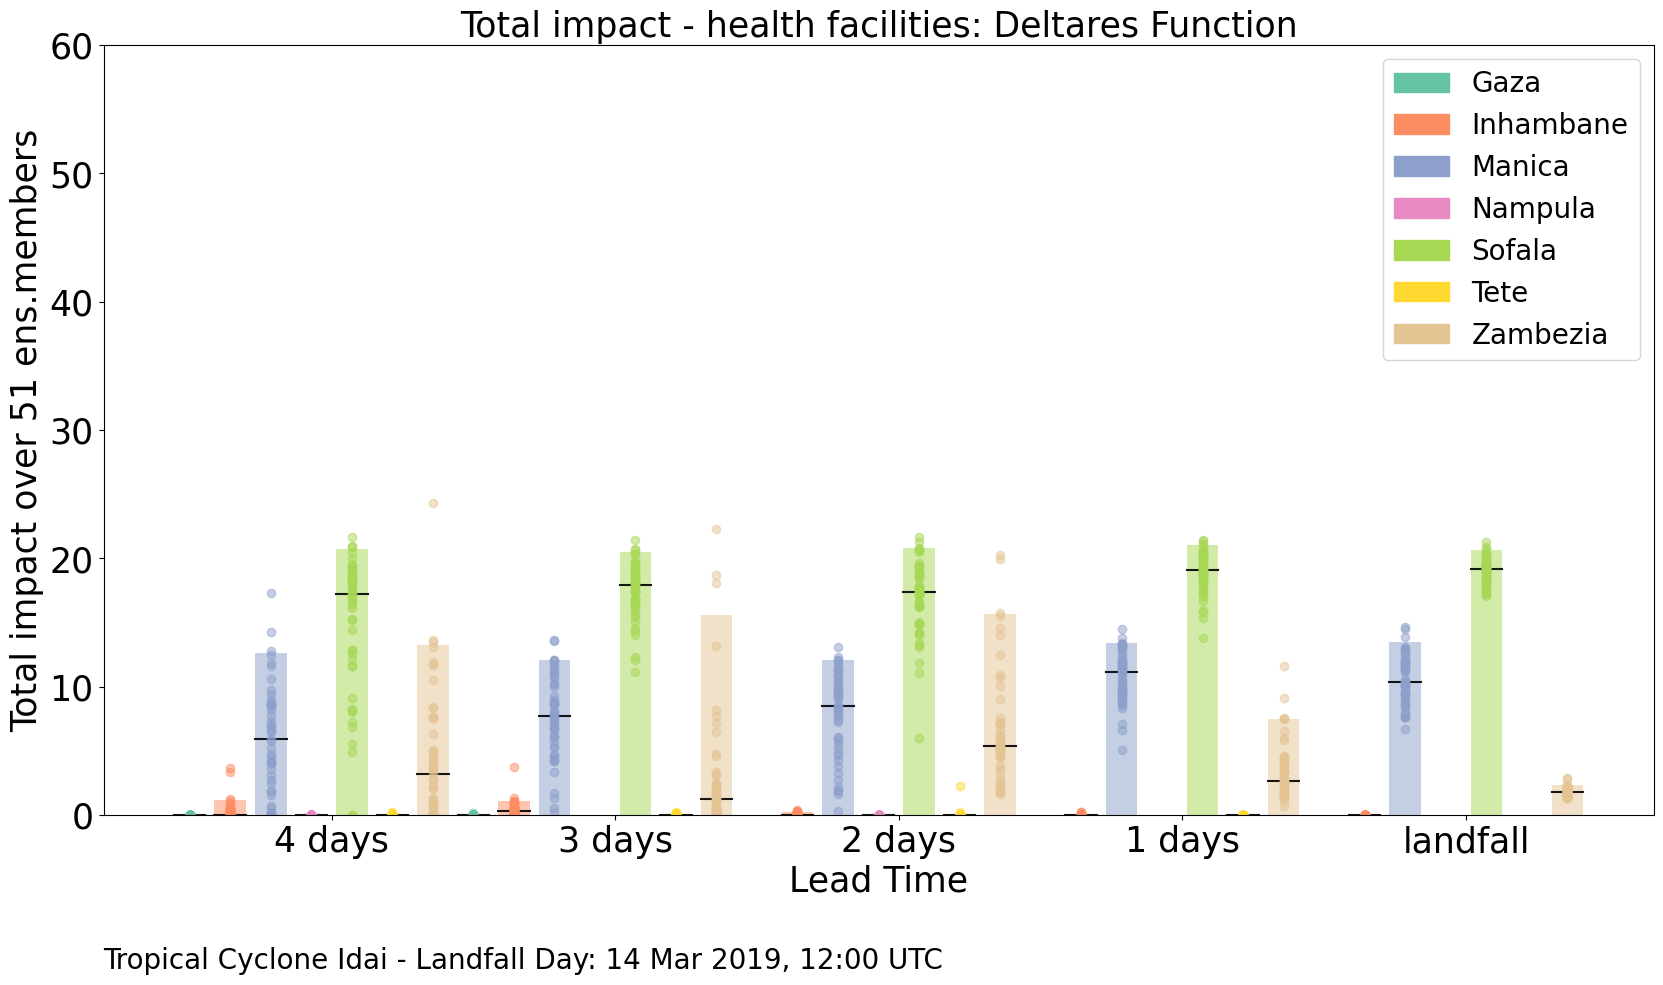

In [151]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Initialize an empty DataFrame for the combined data
combined_melted_df = pd.DataFrame()

# Loop through each key-value pair in the dictionary
for lead_time, df in agg_impact_imph2.items():
    # Melt the DataFrame
    melted_df = df.melt(var_name='Province', value_name='Value')
    melted_df['Lead Time'] = lead_time  # Add the lead time as a new column
    combined_melted_df = pd.concat([combined_melted_df, melted_df])

# Create a figure for the plot
plt.figure(figsize=(20, 10))

# Calculate group_width and offset for positioning
lead_times = combined_melted_df['Lead Time'].unique()
provinces = combined_melted_df['Province'].unique()
num_provinces = len(provinces)

# Set a desired width for the bars and the gap between them
desired_bar_width = 0.7 # Adjust this value to increase the bar width
desired_gap_width = 0.2  # Adjust this value to increase the gap between bars

# Calculate the total width required
total_width = len(lead_times) * num_provinces * (desired_bar_width + desired_gap_width)

# Adjust individual space to include both bar width and gap
individual_space = desired_bar_width + desired_gap_width

# Plot each group
for (province, lead_time), group_data in combined_melted_df.groupby(['Province', 'Lead Time']):
    province_index = list(provinces).index(province)
    lead_time_index = list(lead_times).index(lead_time)

    # Calculate position for each bar
    position = lead_time_index * num_provinces * individual_space + province_index * individual_space

    # Calculate upper whisker and outliers
    upper_whisker = np.quantile(group_data['Value'], 0.95)
    outliers = group_data['Value'][group_data['Value'] > upper_whisker]
    median = np.median(group_data['Value'])

    # Create the boxplot elements
    plt.bar(position, upper_whisker, desired_bar_width, color=province_colors[province], alpha=0.5)
    plt.plot([position - desired_bar_width/2, position + desired_bar_width/2], [median, median], color='black', alpha=0.9)

    # Plot all the values for each province as points
    for value in group_data['Value']:
        plt.plot(position, value, 'o', color=province_colors[province],alpha=0.5)

# Customize the plot
plt.title('Total impact - health facilities: Deltares Function', fontsize=25)
plt.xlabel('Lead Time', fontsize=25)
plt.ylabel('Total impact over 51 ens.members', fontsize=25)

# Set x-ticks for the lead times
plt.xticks([(i * num_provinces + num_provinces / 2) * individual_space for i in range(len(lead_times))], 
           lead_times, rotation=0, fontsize=25)

# Set y-ticks with increased font size
plt.yticks(fontsize=25)
plt.ylim(0, 60)  # Adjust as needed
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S').strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)


# Add legend for provinces
plt.legend([plt.Rectangle((0,0),1,1, color=province_colors[province]) for province in provinces], 
           provinces, loc='upper right', fontsize=20)

figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/Deltares_hfacilities_14032019_dots.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')


# Show the plot
plt.show()

In [152]:
## educational facilities

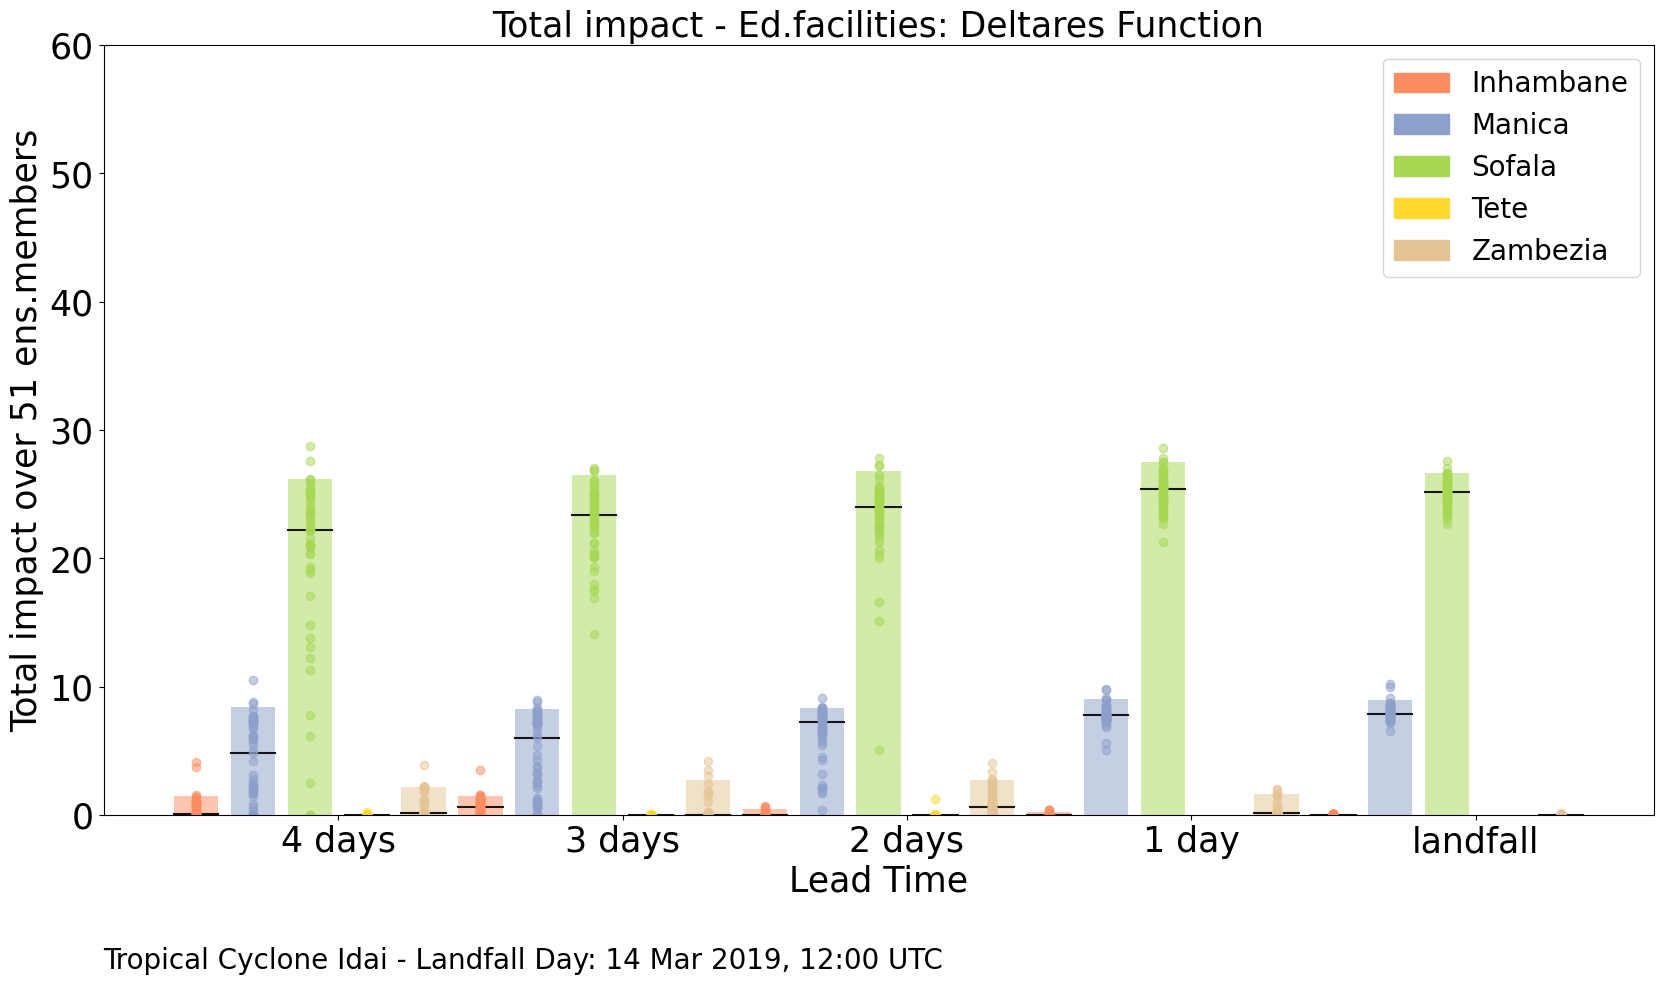

In [153]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Initialize an empty DataFrame for the combined data
combined_melted_df = pd.DataFrame()

# Loop through each key-value pair in the dictionary
for lead_time, df in agg_impact_ed2.items():
    # Melt the DataFrame
    melted_df = df.melt(var_name='Province', value_name='Value')
    melted_df['Lead Time'] = lead_time  # Add the lead time as a new column
    combined_melted_df = pd.concat([combined_melted_df, melted_df])

# Create a figure for the plot
plt.figure(figsize=(20, 10))

# Calculate group_width and offset for positioning
lead_times = combined_melted_df['Lead Time'].unique()
provinces = combined_melted_df['Province'].unique()
num_provinces = len(provinces)

# Set a desired width for the bars and the gap between them
desired_bar_width = 0.7 # Adjust this value to increase the bar width
desired_gap_width = 0.2  # Adjust this value to increase the gap between bars

# Calculate the total width required
total_width = len(lead_times) * num_provinces * (desired_bar_width + desired_gap_width)

# Adjust individual space to include both bar width and gap
individual_space = desired_bar_width + desired_gap_width

# Plot each group
for (province, lead_time), group_data in combined_melted_df.groupby(['Province', 'Lead Time']):
    province_index = list(provinces).index(province)
    lead_time_index = list(lead_times).index(lead_time)

    # Calculate position for each bar
    position = lead_time_index * num_provinces * individual_space + province_index * individual_space

    # Calculate upper whisker and outliers
    upper_whisker = np.quantile(group_data['Value'], 0.95)
    outliers = group_data['Value'][group_data['Value'] > upper_whisker]
    median = np.median(group_data['Value'])

    # Create the boxplot elements
    plt.bar(position, upper_whisker, desired_bar_width, color=province_colors[province], alpha=0.5)
    plt.plot([position - desired_bar_width/2, position + desired_bar_width/2], [median, median], color='black', alpha=0.9)

    # Plot all the values for each province as points
    for value in group_data['Value']:
        plt.plot(position, value, 'o', color=province_colors[province],alpha=0.5)

# Customize the plot
plt.title('Total impact - Ed.facilities: Deltares Function', fontsize=25)
plt.xlabel('Lead Time', fontsize=25)
plt.ylabel('Total impact over 51 ens.members', fontsize=25)

# Set x-ticks for the lead times
plt.xticks([(i * num_provinces + num_provinces / 2) * individual_space for i in range(len(lead_times))], 
           lead_times, rotation=0, fontsize=25)

# Set y-ticks with increased font size
plt.yticks(fontsize=25)
plt.ylim(0, 60)  # Adjust as needed
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S').strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)


# Add legend for provinces
plt.legend([plt.Rectangle((0,0),1,1, color=province_colors[province]) for province in provinces], 
           provinces, loc='upper right', fontsize=20)

# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/Deltares_edfacilities_14032019_dots.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()  # This line can be removed if you don't want to display the plot in the notebook

In [154]:
##population affected 
##HERE JUST agg_impact_pp7 because agg_impact_pp8 does not have any damage on the population, 
##so the forecast did not reach a category 4
### but 7 correspond to category 3, 

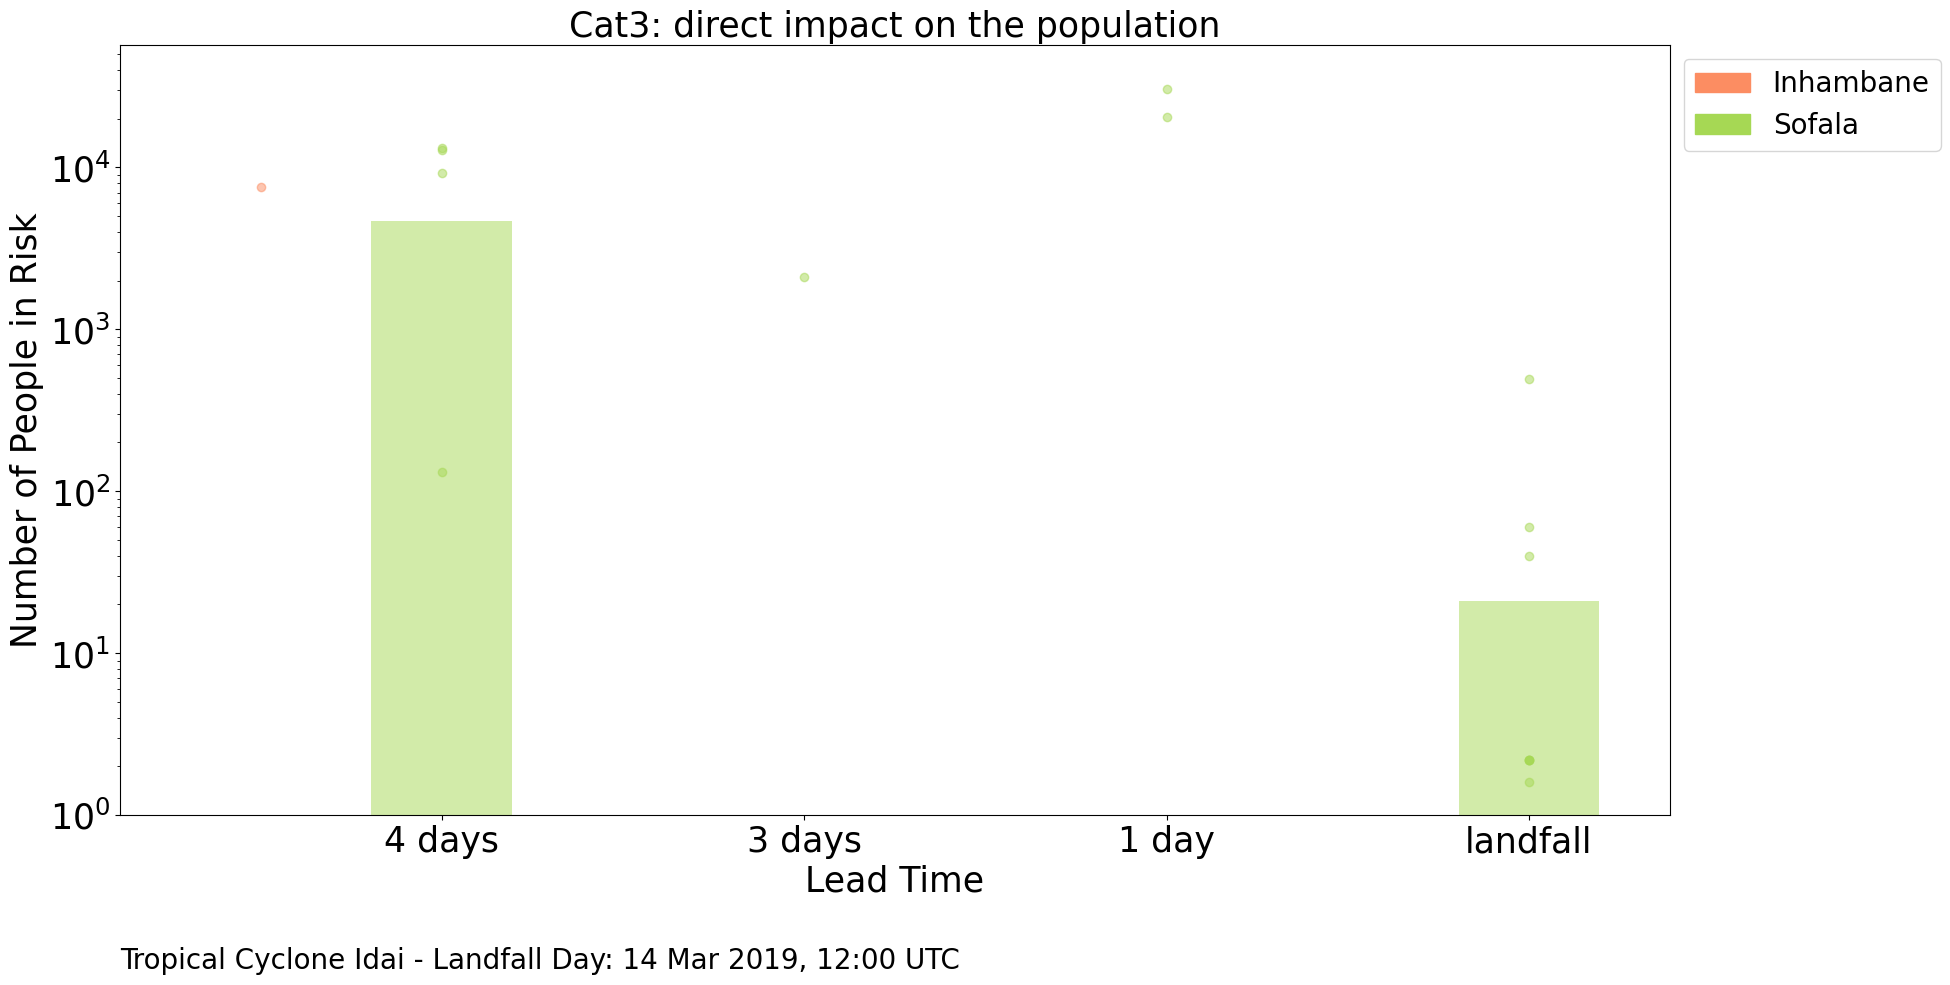

In [155]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Initialize an empty DataFrame for the combined data
combined_melted_df = pd.DataFrame()

# Loop through each key-value pair in the dictionary
for lead_time, df in agg_impact_pp7.items():
    # Melt the DataFrame
    melted_df = df.melt(var_name='Province', value_name='Value')
    melted_df['Lead Time'] = lead_time  # Add the lead time as a new column
    combined_melted_df = pd.concat([combined_melted_df, melted_df])

# Create a figure for the plot
plt.figure(figsize=(20, 10))

# Calculate group_width and offset for positioning
lead_times = combined_melted_df['Lead Time'].unique()
provinces = combined_melted_df['Province'].unique()
num_provinces = len(provinces)

# Set a desired width for the bars and the gap between them
desired_bar_width = 0.7 # Adjust this value to increase the bar width
desired_gap_width = 0.2  # Adjust this value to increase the gap between bars

# Calculate the total width required
total_width = len(lead_times) * num_provinces * (desired_bar_width + desired_gap_width)

# Adjust individual space to include both bar width and gap
individual_space = desired_bar_width + desired_gap_width

for (province, lead_time), group_data in combined_melted_df.groupby(['Province', 'Lead Time']):
    province_index = list(provinces).index(province)
    lead_time_index = list(lead_times).index(lead_time)

    # Calculate position for each bar
    position = lead_time_index * num_provinces * individual_space + province_index * individual_space

    # Calculate upper whisker and outliers
    upper_whisker = np.quantile(group_data['Value'], 0.95)
    outliers = group_data['Value'][group_data['Value'] > upper_whisker]
    median = np.median(group_data['Value'])

    # Create the boxplot elements
    plt.bar(position, upper_whisker, desired_bar_width, color=province_colors[province], alpha=0.5)
    plt.plot([position - desired_bar_width/2, position + desired_bar_width/2], [median, median], color='black', alpha=0.9)

    # Plot all the values for each province as points
    for value in group_data['Value']:
        plt.plot(position, value, 'o', color=province_colors[province],alpha=0.5)

# Customize the plot
plt.title('Cat3: direct impact on the population', fontsize=25)
plt.xlabel('Lead Time', fontsize=25)
plt.ylabel('Number of People in Risk', fontsize=25)
# Set x-ticks for the lead times
plt.xticks([(i * num_provinces + num_provinces / 2) * individual_space for i in range(len(lead_times))], 
           lead_times, rotation=0, fontsize=25)
plt.yticks(fontsize=25)
#plt.ylim(0, 10^7)  # Adjust as needed
# Set the y-axis to a logarithmic scale
plt.yscale('log', base=10)
# Set the y-axis limits to start at 10^0 and an upper limit that you deem appropriate
plt.ylim(bottom=1)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)

# Add legend and show plot
#plt.legend([plt.Rectangle((0,0),1,1, color=province_colors[province]) for province in provinces], provinces, loc='upper right', fontsize=20)
# Add legend and show plot
legend = plt.legend([plt.Rectangle((0,0),1,1, color=province_colors[province]) for province in provinces], provinces, loc='upper left', fontsize=20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1, 1))
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/cat4_dimpact_pp_14032019_dots.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()  # This line can be removed if you don't want to display the plot in the notebook

## people disrupted and people affected whrn a service is disrupted 

In [157]:
key_mapping_disrupt_pp1 = {
    'impp1_MOZ_Idai_20190310120000': '4 days',
    'impp1_MOZ_Idai_20190311120000': '3 days',
    'impp1_MOZ_Idai_20190312120000': '2 days',
    'impp1_MOZ_Idai_20190313120000': '1 day',
    'impp1_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_pp1_plot = {key_mapping_disrupt_pp1[key]: value for key, value in disrupt_pp1.copy().items() if key in key_mapping_disrupt_pp1}

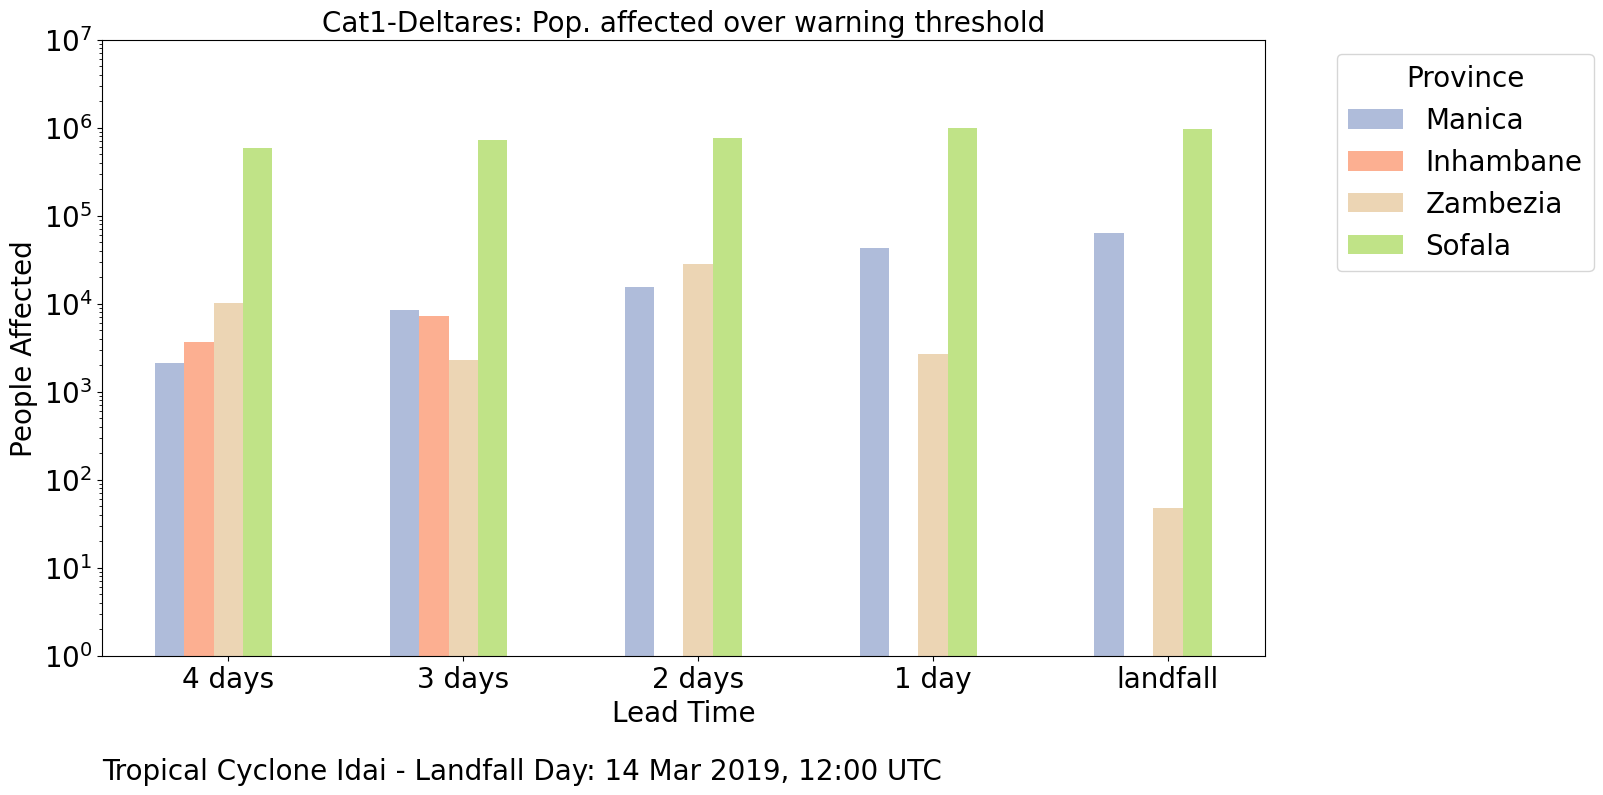

In [159]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_pp1_plot.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_pp1_plot)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(disrupt_pp1_plot.items()):
    province_data = df.groupby('NAME_1')['imp_people'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Cat1-Deltares: Pop. affected over warning threshold', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_pp1_plot.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/Deltares_14032019_ppdisrup.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## people unique disrupted by category 1- Unique 

In [286]:
key_mapping_disrupt_pp1_unique = {
    'impp1_MOZ_Idai_20190310120000': '4 days',
    'impp1_MOZ_Idai_20190311120000': '3 days',
    'impp1_MOZ_Idai_20190312120000': '2 days',
    'impp1_MOZ_Idai_20190313120000': '1 day',
    'impp1_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_pp1_unique_plot = {key_mapping_disrupt_pp1_unique[key]: value for key, value in disrupt_pp1_unique_dict.copy().items() if key in key_mapping_disrupt_pp1_unique}

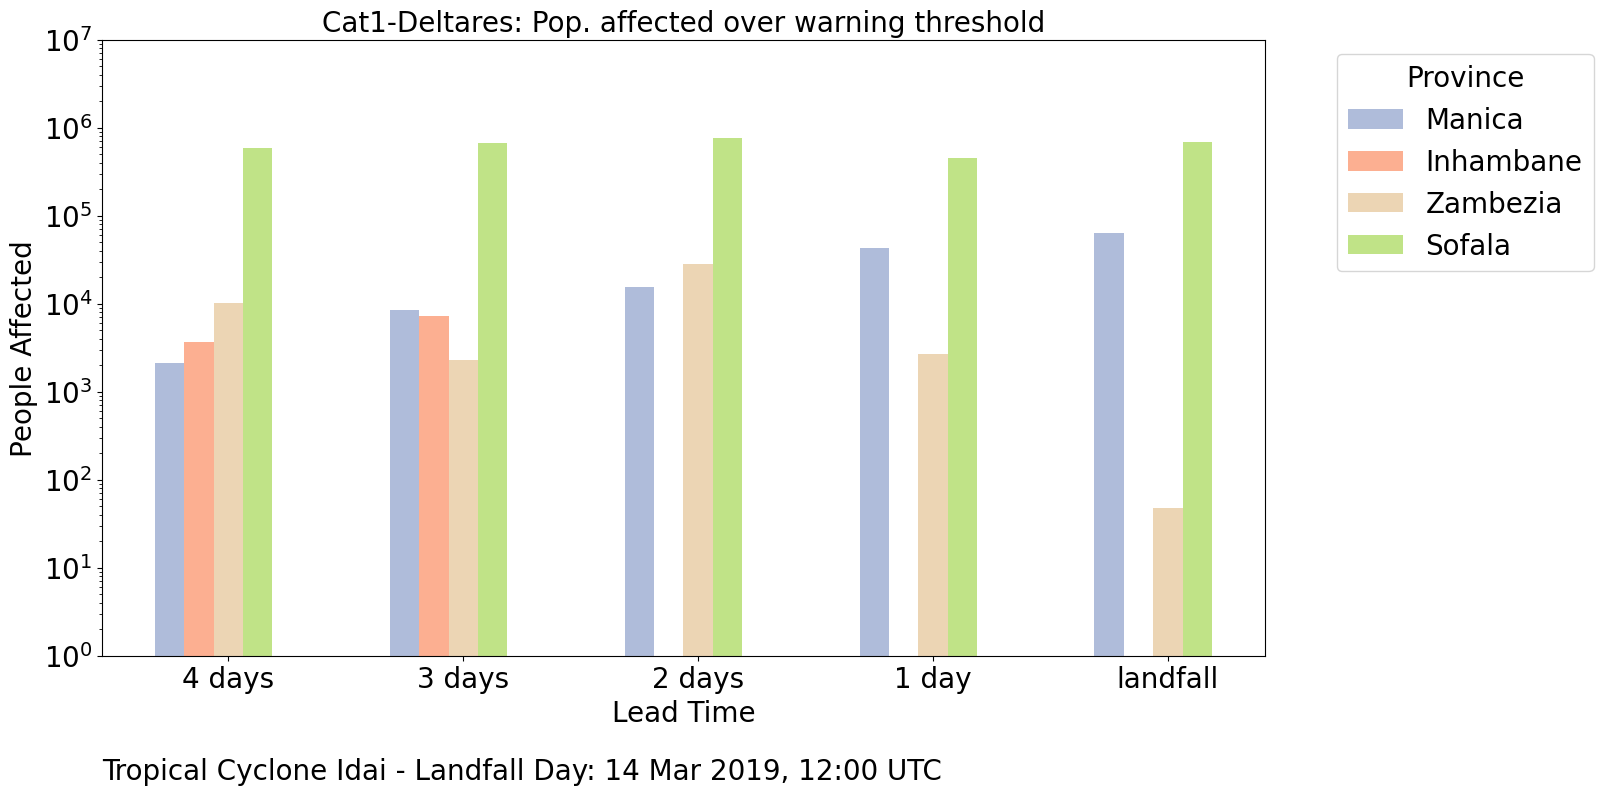

In [289]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_pp1_unique_plot.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_pp1_unique_plot)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(disrupt_pp1_unique_plot.items()):
    province_data = df.groupby('NAME_1')['imp_people'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Cat1-Deltares: Pop. affected over warning threshold', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_pp1_unique_plot.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/Deltares_14032019_ppdisrup_unique_cat1.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [294]:
##People Afffected only for category 1 - unique when imph2 is disrupted 
key_mapping_disrupt_imph2_pp1 = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_imph2_pp1_plot = {key_mapping_disrupt_imph2_pp1[key]: value for key, value in disrupt_imph2_pp1.copy().items() if key in key_mapping_disrupt_imph2_pp1}

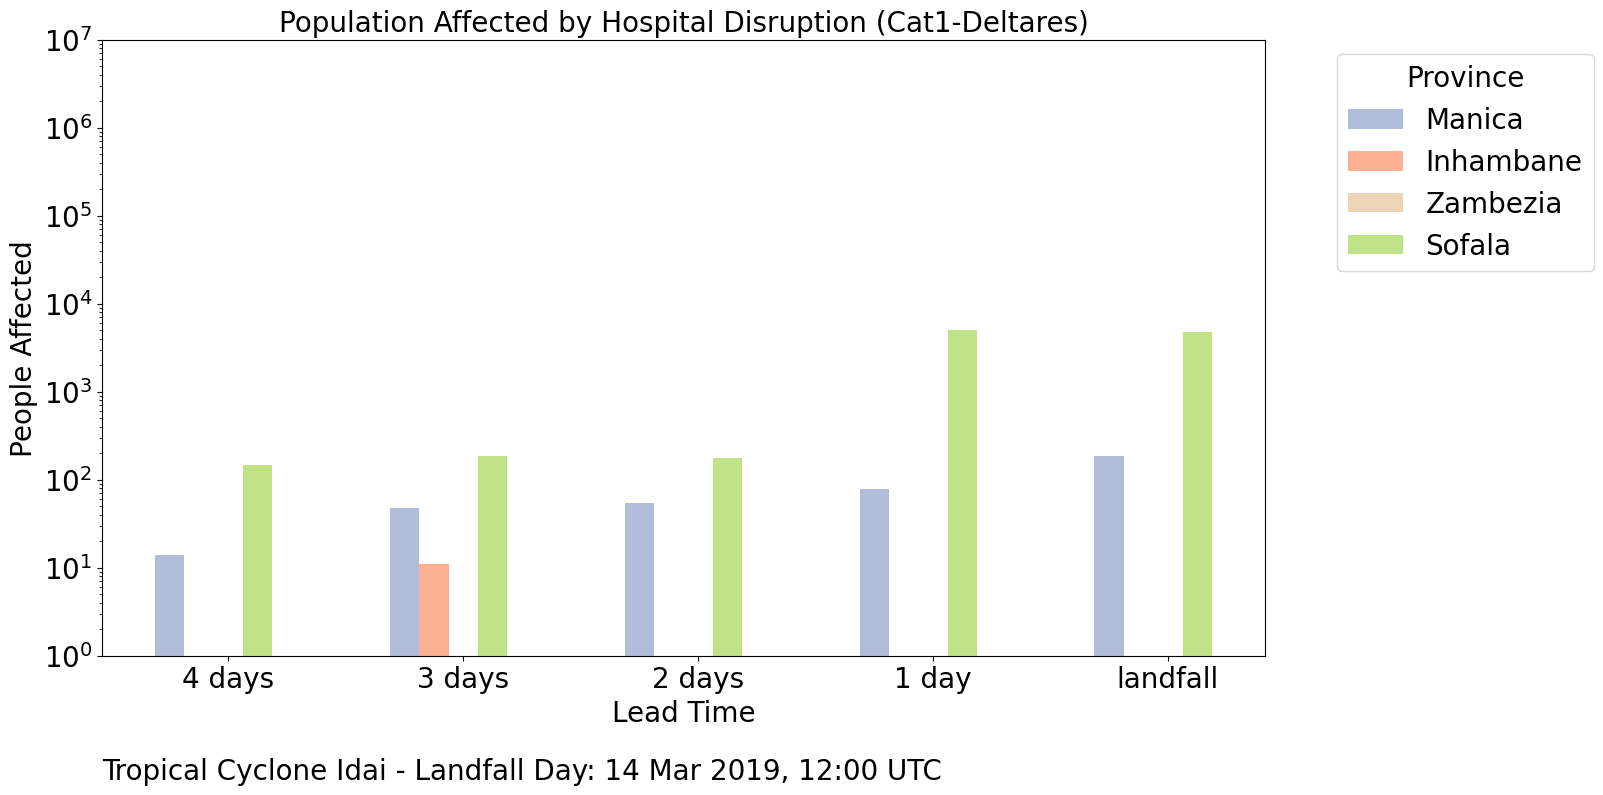

In [311]:
# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_imph2_pp1_plot.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in disrupt_imph2_pp1_plot)
num_groups = len(disrupt_imph2_pp1_plot)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in disrupt_imph2_pp1_plot
for i, (key, df) in enumerate(disrupt_imph2_pp1_plot.items()):
    # Use 'pp_affected' as the column for affected population
    province_data = df.groupby('NAME_1')['pp_affected'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Population Affected by Hospital Disruption (Cat1-Deltares)', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_imph2_pp1_plot.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)

# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)

# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)

# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/peopleaffected_imph2_pp1.jpg"  # Change this to your desired filename
plt.savefig(figure_filename, dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
##people disrupted when 

In [301]:
##People Afffected only for category 1 - unique when imph2 is disrupted 
key_mapping_disrupt_imph2_pp2 = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_imph2_pp2_plot = {key_mapping_disrupt_imph2_pp2[key]: value for key, value in disrupt_imph2_pp2.copy().items() if key in key_mapping_disrupt_imph2_pp2}

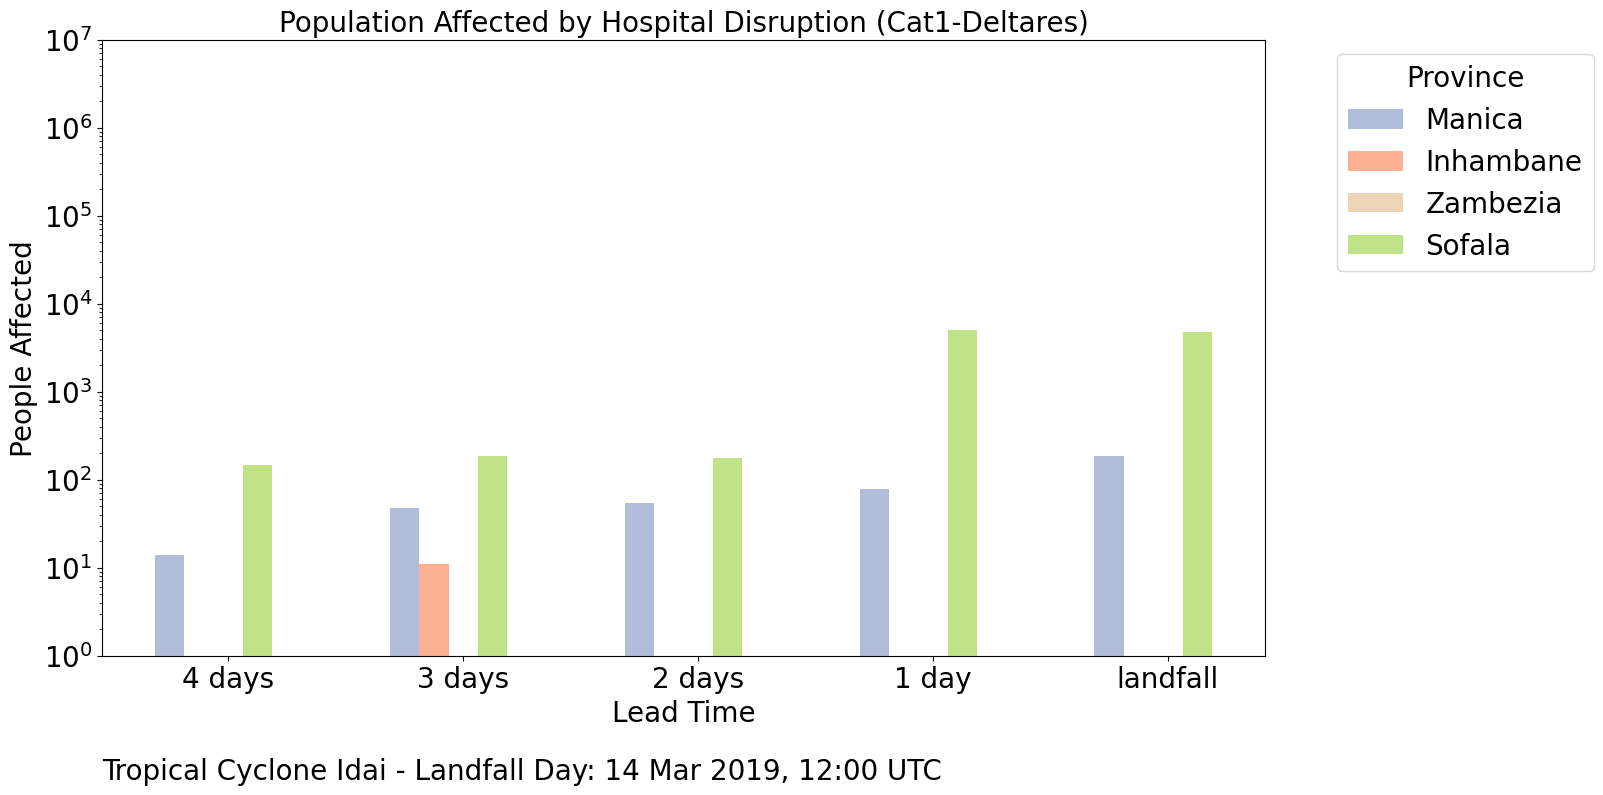

In [312]:
# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_imph2_pp2_plot.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in disrupt_imph2_pp1_plot)
num_groups = len(disrupt_imph2_pp2_plot)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in disrupt_imph2_pp1_plot
for i, (key, df) in enumerate(disrupt_imph2_pp2_plot.items()):
    # Use 'pp_affected' as the column for affected population
    province_data = df.groupby('NAME_1')['pp_affected'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Population Affected by Hospital Disruption (Cat2-Deltares)', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_imph2_pp2_plot.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)

# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)

# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)

# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/peopleaffected_imph2_pp2.jpg"  # Change this to your desired filename
plt.savefig(figure_filename, dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
### people unique affected by category 2 

In [290]:
key_mapping_disrupt_pp2 = {
    'impp2_MOZ_Idai_20190310120000': '4 days',
    'impp2_MOZ_Idai_20190311120000': '3 days',
    'impp2_MOZ_Idai_20190312120000': '2 days',
    'impp2_MOZ_Idai_20190313120000': '1 day',
    'impp2_MOZ_Idai_20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_pp2_plot = {key_mapping_disrupt_pp2[key]: value for key, value in disrupt_pp2.copy().items() if key in key_mapping_disrupt_pp2}

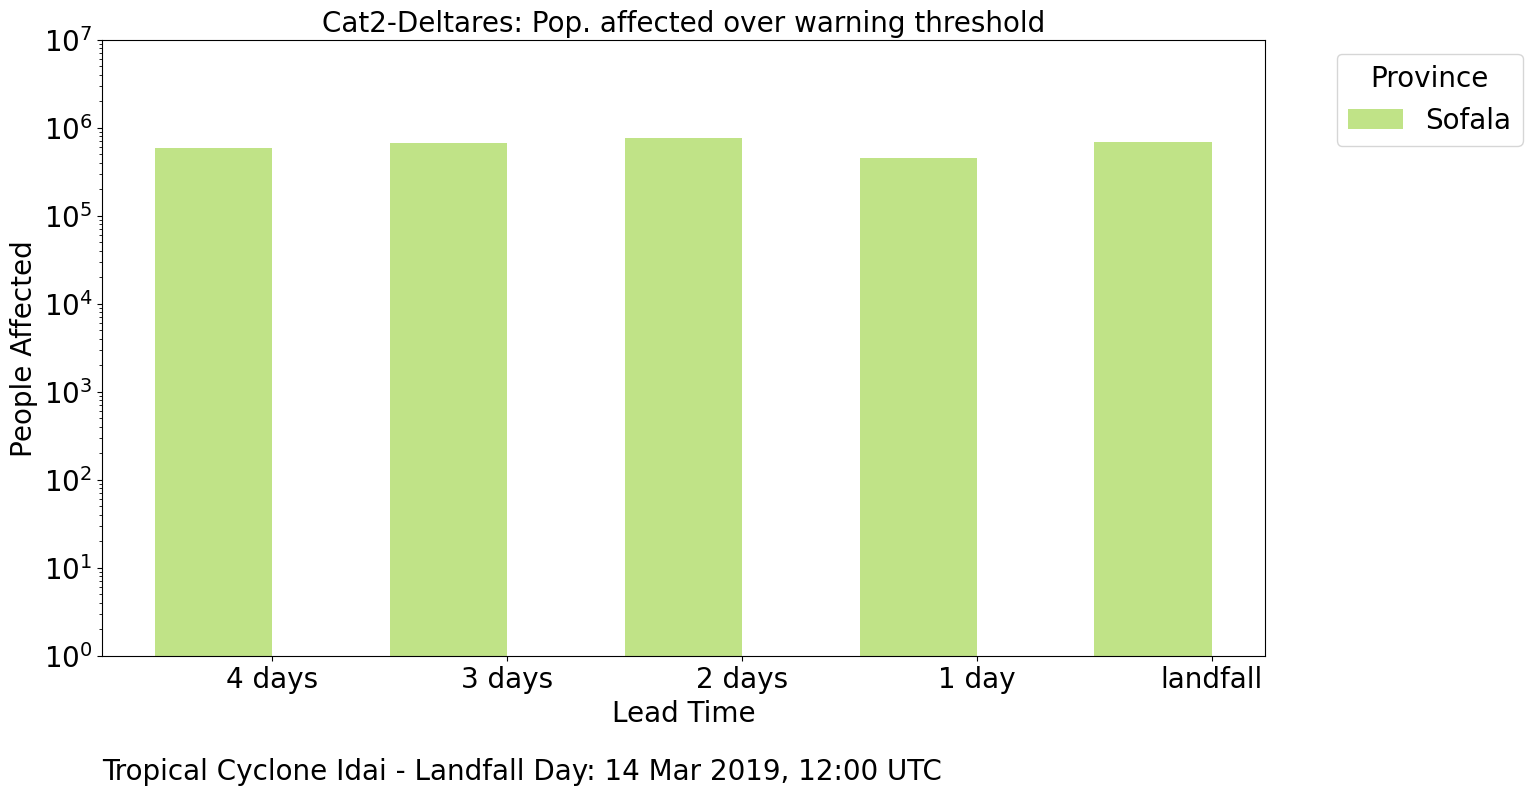

In [291]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Gaza': '#66c2a5',    # Teal
    'Inhambane': '#fc8d62',  # Salmon
    'Manica': '#8da0cb',   # Light Blue
    'Nampula': '#e78ac3',  # Pink
    'Sofala': '#a6d854',   # Light Green
    'Tete': '#ffd92f',     # Yellow
    'Zambezia': '#e5c494'  # Beige
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_pp2_plot.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_pp2_plot)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(disrupt_pp1_unique_plot.items()):
    province_data = df.groupby('NAME_1')['imp_people'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Cat2-Deltares: Pop. affected over warning threshold', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_pp2_plot.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20190314120000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Idai - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/home/gespejogutierrez/programs/MOZ_struc_plots_Idai/Deltares_14032019_ppdisrup_cat2.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## PEOPLE AFFECTED ONCE A SCHOOL IS DISRUPTED 

NameError: name 'disrupt_ed1_unique_dict' is not defined

In [ ]:
###ROADS 

In [136]:
# Define the mapping from old keys to new keys
key_mapping_rd2 = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall'
}
# Create a new dictionary with the updated keys
rd2_mimpact = {key_mapping_rd2[key]: value for key, value in rd2_mimpact.items() if key in key_mapping_rd2}

# Placeholder data for other days (replace with actual data)
data_20230216 = rd2 ['rd2_MDG_new_FREDDY_20230216180000'].at_event/500
data_20230217 = rd2 ['rd2_MDG_new_FREDDY_20230217180000'].at_event/500
data_20230218 = rd2 ['rd2_MDG_new_FREDDY_20230218180000'].at_event/500
data_20230219 = rd2 ['rd2_MDG_new_FREDDY_20230219180000'].at_event/500
data_20230220 = rd2 ['rd2_MDG_new_FREDDY_20230220180000'].at_event/500
data_20230221 = rd2 ['rd2_MDG_new_FREDDY_20230221180000'].at_event/500


# Combining all data into a list
all_data = [data_20230216, data_20230217, data_20230218, data_20230219, data_20230220, data_20230221]

# Calculating the 95th quantile for each day
quantiles_95 = [np.quantile(data, 0.95) for data in all_data]

# Calculating the median for each day
medians = [np.median(data) for data in all_data]

# Plotting
plt.figure(figsize=(15, 6))

# Plot bars for 95th quantiles using one color
bars = plt.bar(range(len(quantiles_95)), quantiles_95, color='blue', alpha=0.5, label='Madagascar')

# Plot dots for individual data points
for i, data in enumerate(all_data):
    plt.scatter([i] * len(data), data, color='blue')

# Add a line on each bar representing the median value
for i, bar in enumerate(bars):
    plt.hlines(medians[i], bar.get_x(), bar.get_x() + bar.get_width(), colors='black', lw=2, alpha=0.5)

# Setting font sizes
plt.xticks(range(len(all_data)), ['5 days', '4 days', '3 days', '2 days', '1 day', 'landfall'], fontsize=22)
plt.yticks(fontsize=22)
plt.ylabel('Road Impact', fontsize=22)
plt.title('Cat2: Total impact on Roads in Madagascar', fontsize=25)

# Adjusting the legend
plt.legend(fontsize=18, title_fontsize='20', loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/rd2_deltares_distrTOTIMPACT.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## HEATMAPS 

# Example usage
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_htmap_imph2_21022023.jpg"
plot_heatmap_inrisk(nh2_risk, '20230216180000', '20230221180000', filename)

# Example usage
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_mimph2_TCFreddy_21022023.jpg"
plot_heatmap_mimp_HF(nh2, '20230216180000', '20230221180000', filename)

# Example usage
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_nfailures_imph2_21022023.jpg"
plot_heatmap_nfailures(nh2_c, '20230216180000', '20230221180000', filename)

In [ ]:
## educational facilities

# Example usage
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_risk_ed2_21022023.jpg"
plot_heatmap_mimp_CI(ned2_risk, '20230216180000', '20230221180000', filename)

# Example usage
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_failure_TCFreddy_21022023.jpg"
plot_heatmap_CI_fail(ned2_fail, '20230216180000', '20230221180000', filename)

## PLOTTING EXPOSURE EDUCATIONAL FACILITIES 

#results = perform_calculations(exposures_dict, exp_key, date_forecast, event_date)
p_ed2_plot = extract_points_to_plot(exposures_dict, 'ed2','20230221180000','20230221180000')
# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 'size': 20},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 'size': 20},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 'size': 30},  # Darker for level 3
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 'size': 40},    # Darker for level 4
}
exp_longitude = p_ed2_plot['longitude']
exp_latitude = p_ed2_plot['latitude']
exp_impact = p_ed2_plot['impact_data'] ['impact']
#exp_levels = p_ed2_plot['level_data']
lead_time = p_ed2_plot ['lead_time']
filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/MDG_Exposures_ed2.jpg"
plotting_tracks = plot_exposure_ed(exp_longitude,exp_latitude,filename)
filename= "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/MDG_20230221180000_strucimpforecast_ed2.jpg"
plotting_tracks = plot_tracks(ens_variables ['ens_FREDDY_20230221180000'],exp_longitude,exp_latitude,exp_impact,filename,0.1,gadm_MOZ,lead_time)

In [ ]:
############ PLOTTING EDUCATIONAL FACILITES PLUS TRACK

In [ ]:
## DISRUPTED FACILITIES AFFECT TO THE POPULATION NEAREST POPULATION 

In [ ]:
popaf_ed2 = calculate_nearest_population(disrupt_ed2, gdf_worldpop_MOZ.gdf)

In [ ]:
#### nearest pop disrupted 

In [ ]:
#disrupt_imph2_pp1 = cal_nearestpop_disrup(disrupt_imph2, disrupt_pp1)
disrupt_ed2_pp1 = cal_nearestpop_disrup(disrupt_ed2, disrupt_pp1)

In [ ]:
## change the name: population affected by disrupted hospitals

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'imph2_MDG_new_FREDDY_20230216180000': '5 days',
    'imph2_MDG_new_FREDDY_20230217180000': '4 days',
    'imph2_MDG_new_FREDDY_20230218180000': '3 days',
    'imph2_MDG_new_FREDDY_20230219180000': '2 days',
    'imph2_MDG_new_FREDDY_20230220180000': '1 day',
    'imph2_MDG_new_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
popaf_imph2 = {key_mapping[key]: value for key, value in popaf_imph2.items() if key in key_mapping}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Antananarivo': 'blue',
    'Antsiranana': 'orange',
    'Fianarantsoa': 'green',
    'Mahajanga': 'red',
    'Toamasina': 'purple',
    'Toliary': 'brown'
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in popaf_imph2.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(popaf_imph2)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(popaf_imph2.items()):
    province_data = df.groupby('NAME_1')['affected_population'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Deltares: People without healthcare access', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, popaf_imph2.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 1000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20230221180000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Freddy - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_pp_without_healthaccess_21022023.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'imph2_MDG_new_FREDDY_20230216180000': '5 days',
    'imph2_MDG_new_FREDDY_20230217180000': '4 days',
    'imph2_MDG_new_FREDDY_20230218180000': '3 days',
    'imph2_MDG_new_FREDDY_20230219180000': '2 days',
    'imph2_MDG_new_FREDDY_20230220180000': '1 day',
    'imph2_MDG_new_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_imph2_pp1 = {key_mapping[key]: value for key, value in disrupt_imph2_pp1.items() if key in key_mapping}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Antananarivo': 'blue',
    'Antsiranana': 'orange',
    'Fianarantsoa': 'green',
    'Mahajanga': 'red',
    'Toamasina': 'purple',
    'Toliary': 'brown'
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in popaf_imph2.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_imph2_pp1)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(disrupt_imph2_pp1.items()):
    province_data = df.groupby('NAME_1')['pp_affected'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Deltares: People direct affected & without healthcare access', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_imph2_pp1.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 1000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20230221180000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Freddy - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_pp_without_healthaccess_21022023_ppdisrup.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## Direct people affected from 0.10 how much people is affected per province

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'impp1_MDG_FREDDY_20230216180000': '5 days',
    'impp1_MDG_FREDDY_20230217180000': '4 days',
    'impp1_MDG_FREDDY_20230218180000': '3 days',
    'impp1_MDG_FREDDY_20230219180000': '2 days',
    'impp1_MDG_FREDDY_20230220180000': '1 day',
    'impp1_MDG_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_pp1 = {key_mapping[key]: value for key, value in disrupt_pp1.items() if key in key_mapping}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Antananarivo': 'blue',
    'Antsiranana': 'orange',
    'Fianarantsoa': 'green',
    'Mahajanga': 'red',
    'Toamasina': 'purple',
    'Toliary': 'brown'
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_pp1.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_pp1)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(disrupt_pp1.items()):
    province_data = df.groupby('NAME_1')['imp_people'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Deltares: Pop. affected over warning threshold', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_pp1.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 10000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20230221180000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Freddy - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_21022023_ppdisrup.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## Pop affected in the schools 

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'ed2_MDG_new_FREDDY_20230216180000': '5 days',
    'ed2_MDG_new_FREDDY_20230217180000': '4 days',
    'ed2_MDG_new_FREDDY_20230218180000': '3 days',
    'ed2_MDG_new_FREDDY_20230219180000': '2 days',
    'ed2_MDG_new_FREDDY_20230220180000': '1 day',
    'ed2_MDG_new_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
popaf_ed2 = {key_mapping[key]: value for key, value in popaf_ed2.items() if key in key_mapping}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Antananarivo': 'blue',
    'Antsiranana': 'orange',
    'Fianarantsoa': 'green',
    'Mahajanga': 'red',
    'Toamasina': 'purple',
    'Toliary': 'brown'
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in popaf_ed2.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(popaf_ed2)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(popaf_ed2.items()):
    province_data = df.groupby('NAME_1')['affected_population'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Deltares: Pop without educ. access', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, popaf_ed2.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 1000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20230221180000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Freddy - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_pp_without_schools_21022023.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## people disrupted and also with not schools access 

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'ed2_MDG_new_FREDDY_20230216180000': '5 days',
    'ed2_MDG_new_FREDDY_20230217180000': '4 days',
    'ed2_MDG_new_FREDDY_20230218180000': '3 days',
    'ed2_MDG_new_FREDDY_20230219180000': '2 days',
    'ed2_MDG_new_FREDDY_20230220180000': '1 day',
    'ed2_MDG_new_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_ed2_pp1 = {key_mapping[key]: value for key, value in disrupt_ed2_pp1.items() if key in key_mapping}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter

# Define the color mapping for each province
province_colors = {
    'Antananarivo': 'blue',
    'Antsiranana': 'orange',
    'Fianarantsoa': 'green',
    'Mahajanga': 'red',
    'Toamasina': 'purple',
    'Toliary': 'brown'
}

# Create a figure for the plot
plt.figure(figsize=(15, 8))

# Generate a list of unique provinces and add them to non_zero_provinces
unique_provinces = set(province for df in disrupt_ed2_pp1.values() for province in df['NAME_1'])
non_zero_provinces = set(unique_provinces)

# Number of groups (one for each key in popaf_imph2)
num_groups = len(disrupt_ed2_pp1)

# Width of each bar
bar_width = 0.5 / len(unique_provinces)

# Initial position of the first group of bars
initial_group_positions = np.arange(num_groups)

# Iterate through each key and DataFrame in popaf_imph2
for i, (key, df) in enumerate(popaf_ed2.items()):
    province_data = df.groupby('NAME_1')['pp_affected'].sum()

    for j, province in enumerate(unique_provinces):
        affected = province_data.get(province, 0)
        color = province_colors.get(province, 'gray')
        bar_position = initial_group_positions[i] + j * bar_width
        plt.bar(bar_position, affected, bar_width, color=color, label=province if i == 0 else '', alpha=0.7)

# Customize the plot
plt.title('Deltares: Pop affected & without educ. access', fontsize=20)
plt.xlabel('Lead Time', fontsize=20)
plt.ylabel('People Affected', fontsize=20)
plt.xticks(initial_group_positions + bar_width * len(unique_provinces) / 2, disrupt_ed2_pp1.keys(), fontsize=20)
plt.yticks(fontsize=20)
plt.yscale('log')
plt.ylim(1, 1000000)
plt.yscale('log')
# Add legend
handles, labels = plt.gca().get_legend_handles_labels()
unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
# Create the legend and adjust its size
legend = plt.legend(*zip(*unique), loc='upper left', title='Province', fontsize=20)
legend.get_title().set_fontsize(20)
# Move the legend outside the plot to the right
legend.set_bbox_to_anchor((1.05, 1))
plt.grid(axis='y', linestyle='', alpha=0.7)
# Add text for the day of landfall near the legend
landfall_date = pd.to_datetime("20230221180000", format='%Y%m%d%H%M%S', utc=True).strftime('%d %b %Y, %H:%M UTC')
plt.text(x=0, y=-0.2, s=f'Tropical Cyclone Freddy - Landfall Day: {landfall_date}', transform=plt.gca().transAxes, fontsize=20)
# Show the plot
# Save the figure to a file (specify your desired filename and format)
figure_filename = "/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/Deltares_pp_without_schools_21022023_disruptedpp.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
# PLOTS FOR POPULATION IN GRAY ONLY POP ABOVE 0 VALUE AND DISRUPTED HOSPITALS AROUND
# TO VISUALIZE BETTER 
# First worldpop, all the population and the disruption
# Second only pp affected disrupted and hospitals disrupted

In [ ]:
# Round the values in the 'people' column
gdf_worldpop_MDG.gdf['people'] = gdf_worldpop_MDG.gdf['people'].round()

# Keep only rows where 'people' > 1
gdf_worldpop_MDG.gdf = gdf_worldpop_MDG.gdf[gdf_worldpop_MDG.gdf['people'] > 1]

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'imph2_MDG_new_FREDDY_20230216180000': '5 days',
    'imph2_MDG_new_FREDDY_20230217180000': '4 days',
    'imph2_MDG_new_FREDDY_20230218180000': '3 days',
    'imph2_MDG_new_FREDDY_20230219180000': '2 days',
    'imph2_MDG_new_FREDDY_20230220180000': '1 day',
    'imph2_MDG_new_FREDDY_20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_imph2 = {key_mapping[key]: value for key, value in disrupt_imph2.items() if key in key_mapping}

In [ ]:
import matplotlib.pyplot as plt

# Iterate over each key in the disrupt_imph1 dictionary
for key in disrupt_imph2:
    # Create a figure for each key
    fig, ax = plt.subplots(figsize=(20, 20))

    # Plot administrative boundaries first
    gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=1.5)

    # Plot data from worldpop
    gdf_worldpop_MDG.plot(ax=ax, color='lightgray', markersize=0.5, alpha=0.5)

    # Plot the data from the current key in disrupt_imph1 last to be on top
    disrupt_imph2[key].plot(ax=ax, color='red', markersize=30)

    # Set the limits for the axes to zoom in on the specified region
    ax.set_xlim(44, 50)
    ax.set_ylim(-24, -16)

    # Setting labels and title
    ax.set_xlabel('Longitude',fontsize=40)
    ax.set_ylabel('Latitude',fontsize=40)
    ax.set_title(f'Lead time:{key}',fontsize=40)
    ax.tick_params(axis='both', which='major', labelsize=40)
    
    # Save the figure with a unique filename based on the key
    fig.savefig(f'/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/{key}_deltah2disrup_worldpop_21022023.jpg', dpi=300)  # Change the format and resolution as needed

    # Close the figure to release memory
    plt.close(fig)

    # Show the plot for the current key
    plt.show()

In [ ]:
## educational schools

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    'ed2_MDG_new_FREDDY_20230216180000': '5 days',
    'ed2_MDG_new_FREDDY_20230217180000': '4 days',
    'ed2_MDG_new_FREDDY_20230218180000': '3 days',
    'ed2_MDG_new_FREDDY_20230219180000': '2 days',
    'ed2_MDG_new_FREDDY_20230220180000': '1 day',
    'ed2_MDG_new_FREDDY_20230221180000': 'landfall'
}

# Create a new dictionary with the updated keys
disrupt_ed2 = {key_mapping[key]: value for key, value in disrupt_ed2.items() if key in key_mapping}

In [ ]:
import matplotlib.pyplot as plt

# Iterate over each key in the disrupt_imph1 dictionary
for key in disrupt_ed2:
    # Create a figure for each key
    fig, ax = plt.subplots(figsize=(20, 20))

    # Plot administrative boundaries first
    gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=1.5)

    # Plot data from worldpop
    gdf_worldpop_MDG.plot(ax=ax, color='lightgray', markersize=0.5, alpha=0.5)

    # Plot the data from the current key in disrupt_imph1 last to be on top
    disrupt_ed2[key].plot(ax=ax, color='blue', markersize=30)

    # Set the limits for the axes to zoom in on the specified region
    ax.set_xlim(44, 50)
    ax.set_ylim(-24, -16)

    # Setting labels and title
    ax.set_xlabel('Longitude',fontsize=40)
    ax.set_ylabel('Latitude',fontsize=40)
    ax.set_title(f'Lead time:{key}',fontsize=40)
    ax.tick_params(axis='both', which='major', labelsize=40)
    
    # Save the figure with a unique filename based on the key
    fig.savefig(f'/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/{key}_deltaed2disrup_wpop_21022023.jpg', dpi=600)  # Change the format and resolution as needed

    # Close the figure to release memory
    plt.close(fig)

    # Show the plot for the current key
    plt.show()

In [ ]:
## PLOT FOR THE CASE THAT EXISTS DISRUPTION OF THE PEOPLE AND DISRUPTION OF THE HOSPITALS 

In [ ]:
# Iterate over each key in the dictionary and filter the DataFrame
for key in disrupt_pp1:
    # Round the values in the 'imp_people' column
    disrupt_pp1[key]['imp_people'] = disrupt_pp1[key]['imp_people'].round()

    # Filter to keep only rows where 'imp_people' > 1
    disrupt_pp1[key] = disrupt_pp1[key][disrupt_pp1[key]['imp_people'] > 0]

In [ ]:
# Define marker shapes for different levels
level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
# Define a dictionary to map levels to their alpha, edgecolor, and facecolor settings
level_style = {
    1: {'alpha': 0.7, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 40},
    2: {'alpha': 0.7, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 40},
    3: {'alpha': 0.7, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 50},
    4: {'alpha': 0.7, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 60},
}

In [ ]:
import matplotlib.pyplot as plt

for impp1_key, imph2_key in zip(disrupt_pp1, disrupt_imph2):
    fig, ax = plt.subplots(figsize=(20, 20))

    # Plot the data from disrupt_pp1 for the current date
    if impp1_key in disrupt_pp1:
        disrupt_pp1[impp1_key].plot(ax=ax, color='lightgray', markersize=0.5)

    # Plot administrative boundaries
    gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=1.5)

    # Plot data from disrupt_imph2 for the current date
    if imph2_key in disrupt_imph2:
        df = disrupt_imph2[imph2_key]
        for level in df['levels'].unique():
            level_df = df[df['levels'] == level]
            ax.scatter(level_df['longitude'], level_df['latitude'], 
                       marker=level_markers[level], 
                       **level_style[level])

    # Setting labels, title, and axes limits
    ax.set_xlabel('Longitude', fontsize=40)
    ax.set_ylabel('Latitude', fontsize=40)
    ax.set_title(f'Lead time: {impp1_key}', fontsize=40)
    ax.set_xlim(44, 50)
    ax.set_ylim(-24, -16)
    ax.tick_params(axis='both', which='major', labelsize=40)

    # Save the figure with a unique filename based on the key
    # Uncomment the following line and ensure the directory exists
    fig.savefig(f'/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/{impp1_key}_deltah2_pp1_disrup_21022023.jpg', dpi=600)
    plt.show()

In [ ]:
## Educational facilities 

In [ ]:
import matplotlib.pyplot as plt

# Assuming both dictionaries have matching keys for the dates from 19th to 24th February
for impp1_key, imph2_key in zip(disrupt_pp1, disrupt_ed2):
    # Create a figure for each date
    fig, ax = plt.subplots(figsize=(20, 20))

    # Plot the data from disrupt_impp1 for the current date
    disrupt_pp1[impp1_key].plot(ax=ax, color='lightgray', markersize=0.5)

    # Plot administrative boundaries
    gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=1.5)

    # Plot data from disrup_imph1 for the current date
    disrupt_ed2[imph2_key].plot(ax=ax, color='blue', markersize=30)

    # Set the limits for the axes to focus on the specified region
    ax.set_xlim(44, 50)
    ax.set_ylim(-24, -16)
    
    # Setting labels and title
    ax.set_xlabel('Longitude',fontsize=40)
    ax.set_ylabel('Latitude',fontsize=40)
    ax.set_title(f'Lead time: {impp1_key}',fontsize=40)

    ax.tick_params(axis='both', which='major', labelsize=40)

    # Save the figure with a unique filename based on the key
    fig.savefig(f'/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/{impp1_key}_deltaed2_pp1_disrup_21022023.jpg', dpi=600)  # Change the format and resolution as needed

    # Close the figure to release memory
    plt.show()

In [ ]:
## ROADS

In [ ]:
import geopandas as gpd
from geopandas.tools import sjoin

def process_time_cases(disrupt_rd1, disrup_pp1):
    # Buffer distance for 2 km in degrees
    buffer_distance_2km_deg = 2 / 111  # 2 km converted to degrees

    # Dictionary to store results
    results_dict = {}

    # Assuming your data is already loaded into disrupt_rd1 and disrup_pp1
    for time_case in disrupt_rd1.keys():
        # 1. Buffer the Linestrings
        disrupt_rd1[time_case]['buffered_geometry'] = disrupt_rd1[time_case].geometry.buffer(buffer_distance_2km_deg)

        # Set the buffered geometry as the active geometry
        disrupt_rd1[time_case].set_geometry('buffered_geometry', inplace=True)

        # Rename the existing 'index_right' column to avoid conflict
        disrup_pp1[f'{time_case}'].rename(columns={'index_right': 'NAME_index'}, inplace=True)

        # Perform the spatial join as before
        jn_dfs = sjoin(disrup_pp1[f'{time_case}'], disrupt_rd1[time_case], how='inner', predicate='intersects')

        # Assuming jn_dfs is your GeoDataFrame
        import geopandas as gpd

        # Group by 'geometry_orig' and sum the 'people' column for each group
        population_by_linestring = jn_dfs.groupby('geometry_orig').agg({
        'imp_people': 'sum',  # summing up the people
        'longitude': 'first',  # keeping the first longitude value
        'latitude': 'first',  # keeping the first latitude value
        'geometry': 'first',  # keeping the first geometry value
        'index_right': 'first',  # keeping the first index_right value
        'osm_id': 'first',  # keeping the first osm_id value
        'mean_impact': 'first'  # keeping the first mean_impact value
        }).reset_index()
        # Convert the result back to a GeoDataFrame if you need to perform spatial operations
        population_by_linestring_gdf = gpd.GeoDataFrame(population_by_linestring, geometry='geometry_orig')

        # Save the result in the dictionary with the time_case as the key
        results_dict[time_case] = population_by_linestring_gdf

    return results_dict

In [ ]:
# Define the mapping from old keys to new keys
key_mapping = {
    '20230216180000': '5 days',
    '20230217180000': '4 days',
    '20230218180000': '3 days',
    '20230219180000': '2 days',
    '20230220180000': '1 day',
    '20230221180000': 'landfall'
}
# Create a new dictionary with the updated keys
disrupt_rd2 = {key_mapping[key]: value for key, value in disrupt_rd2.items() if key in key_mapping}

In [ ]:
# Example usage
data_rd2_map = process_time_cases(disrupt_rd2, disrupt_pp1)

In [ ]:
### histogram of people affected by roads TOTAL PEOPLE WORLPOP

In [ ]:
# Initialize a dictionary to store the top 5% data for each key
top_1_percent_dict = {}

# Iterate through each key-value pair in the dictionary
for key, df in data_rd2_map.items():
    # Sort the DataFrame by 'mean_impact' in descending order
    sorted_df = df.sort_values(by='mean_impact', ascending=False)

    # Calculate the number of rows to select (5% of the total rows)
    num_rows_to_select = int(len(df) * 0.01)

    # Select the top 1% highest values and their corresponding rows
    top_1_percent = sorted_df.head(num_rows_to_select)

    # Store the result in the new dictionary
    top_1_percent_dict[key] = top_1_percent

In [ ]:
# Calculating sums for each day and creating a table
pop_1percent = {
    'Lead Time': ['5 days', '4 days', '3 days', '2 days', '1 day', 'landfall'],
    'People Affected': [
        top_1_percent_dict ['5 days'] ['imp_people'].sum(),
        top_1_percent_dict ['4 days'] ['imp_people'].sum(),
        top_1_percent_dict ['3 days'] ['imp_people'].sum(),
        top_1_percent_dict ['2 days'] ['imp_people'].sum(),
        top_1_percent_dict ['1 day'] ['imp_people'].sum(),
        top_1_percent_dict ['landfall'] ['imp_people'].sum()
    ]
}

# Creating DataFrame
popaff_disrupt1_road2 = pd.DataFrame(pop_1percent)

popaff_disrupt1_road2

In [ ]:
# Plotting the bar chart
plt.figure(figsize=(10, 8))
plt.bar(popaff_disrupt1_road2['Lead Time'], popaff_disrupt1_road2['People Affected'], color='midnightblue',alpha=0.8)
plt.title('People affected & people without road network access',fontsize=20)
plt.xlabel('Lead Time',fontsize=20)
plt.ylabel('People Affected',fontsize=20)
plt.xticks(rotation=0)  # Rotating the x-axis labels for better readability
plt.xticks(rotation=0, fontsize=20)  # Increase fontsize as needed
plt.yticks(fontsize=20)  # Increase fontsize as needed
figure_filename = "/cluster/project/climate/gespejo/MDG_plots/cat2_road2disrup_pp2disrupt_1percentilemaxvl_MDG.jpg"  # Change this to your desired filename
plt.savefig(figure_filename,dpi=600, bbox_inches='tight', format='jpg')  # You can adjust dpi as needed
plt.show()

In [ ]:
## People affected by road disrupted: Total people affected (under threshold)by wind and people affected by road disruption

In [ ]:
import geopandas as gpd
from geopandas.tools import sjoin

def tpop_affected_roaddis(disrupt_rd1,glob_pop):
    # Buffer distance for 2 km in degrees
    buffer_distance_2km_deg = 2 / 111  # 2 km converted to degrees

    # Dictionary to store results
    js_results = {}

    # Assuming your data is already loaded into disrupt_rd1 and disrup_pp1
    for time_case in disrupt_rd1.keys():
        # 1. Buffer the Linestrings
        disrupt_rd1[time_case]['buffered_geometry'] = disrupt_rd1[time_case].geometry.buffer(buffer_distance_2km_deg)

        # Set the buffered geometry as the active geometry
        disrupt_rd1[time_case].set_geometry('buffered_geometry', inplace=True)

        # Rename the existing 'index_right' column to avoid conflict
        #disrup_pp1[f'{time_case}'].rename(columns={'index_right': 'NAME_index'}, inplace=True)
        
        # sjoin
        jn_dfs = sjoin(glob_pop, disrupt_rd1[time_case], how='inner', predicate='intersects')
        
        population_by_linestring = jn_dfs.groupby(['geometry_orig', 'osm_id']).agg({
        'people': 'sum',      # summing up the people
        'longitude': 'first',     # keeping the first longitude value
        'latitude': 'first',      # keeping the first latitude value
        'geometry': 'first',      # keeping the first geometry value
        'index_right': 'first',   # keeping the first index_right value
        'mean_impact': 'first'    # keeping the first mean_impact value
            }).reset_index()

        # Convert the result back to a GeoDataFrame if you need to perform spatial operations
        population_by_linestring_gdf = gpd.GeoDataFrame(population_by_linestring, geometry='geometry_orig')

        # Save the result in the dictionary with the time_case as the key
        js_results[time_case] = population_by_linestring_gdf

        # Store the result in the dictionary
        js_results[time_case] = jn_dfs

    return js_results

In [ ]:
# Example usage
data_rd2_map_wlpop = tpop_affected_roaddis(disrupt_rd2,gdf_worldpop_MDG.gdf)

In [ ]:
import matplotlib.pyplot as plt

# Assuming both dictionaries have matching keys for the dates from 19th to 24th February
for impp1_key, imph2_key in zip(disrupt_pp1, data_rd2_map):
    # Create a figure for each date
    fig, ax = plt.subplots(figsize=(20, 20))

    # Plot the data from disrupt_pp1 for the current date
    disrupt_pp1[impp1_key].plot(ax=ax, color='lightgray', markersize=0.2)

    # Plot administrative boundaries
    gadm_MDG.plot(ax=ax, facecolor='none', edgecolor='gray', linewidth=1)

    # Plot data from disrupt_rd1 for the current date with custom edgecolor and linewidth
    data_rd2_map[imph2_key].plot(ax=ax, color='purple', linewidth=0.5, alpha=0.7)

    # Set the limits for the axes to focus on the specified region
    ax.set_xlim(44, 50)
    ax.set_ylim(-24, -16)

    # Setting labels and title
    ax.set_xlabel('Longitude', fontsize=40)
    ax.set_ylabel('Latitude', fontsize=40)
    ax.set_title(f'Lead time: {impp1_key}', fontsize=40)

    ax.tick_params(axis='both', which='major', labelsize=40)
    
    # Save the figure with a unique filename based on the key
    fig.savefig(f'/cluster/project/climate/gespejo/MDG_struc_plots_Freddy/{impp1_key}_deltaroad2_pp1_21022023.jpg', dpi=600)  # Change the format and resolution as needed
    plt.show()
    # Close the figure to release memory
    #plt.close(fig)